# Trabalho 1 — Seoul Bike Sharing Demand (Regressão)
**Unidade Curricular:** Inteligência Artificial (ESTGA) · **Grupo:** Jéssica & Nadia

**Problema:** prever `Rented Bike Count` (bicicletas alugadas por hora) → **regressão**.

Este notebook contém o trabalho completo: a preparação dos dados e os baselines (Parte I), a exploração detalhada e os modelos lineares (Parte II), os modelos não lineares e o diagnóstico de erros (Parte III) e a síntese comparativa com a discussão crítica (Parte IV).

| Parte | Secções | Conteúdo |
| --- | --- | --- |
| I — Dados, preparação e baselines | 1 a 7 | Carregar, limpeza, features, split, avaliação, baselines |
| II — Exploração e modelos lineares | 8 a 12 | EDA, polinómio, Ridge, Lasso, hora categórica, `GridSearchCV` |
| III — Modelos não lineares e diagnóstico | 13 a 17 | Árvore de decisão, Random Forest, otimização, importância, resíduos |
| IV — Síntese comparativa | 18 | Tabela geral |

**Regras comuns:** mesmo split cronológico (80% / 20%), mesma função `avaliar()`, escolha de variantes e hiperparâmetros pela validação cruzada temporal (`tscv`), e teste usado apenas para medir.

# PARTE I — DADOS, PREPARAÇÃO E BASELINES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import TimeSeriesSplit, cross_validate, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

RANDOM_STATE = 100
TEST_FRAC = 0.20          # últimos 20% do tempo vão para teste
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

## 1. Carregamento dos Dados
O CSV tem o símbolo `°C`, por isso é lido com `encoding="latin1"`. Renomeamos as colunas para nomes curtos, sem espaços nem unidades; nenhum valor é alterado.

In [2]:
df_raw = pd.read_csv("SeoulBikeData.csv", encoding="latin1")
df = df_raw.rename(columns={
    "Date": "date", "Rented Bike Count": "count", "Hour": "hour",
    "Temperature(°C)": "temp", "Humidity(%)": "humidity", "Wind speed (m/s)": "wind",
    "Visibility (10m)": "visibility", "Dew point temperature(°C)": "dew_point",
    "Solar Radiation (MJ/m2)": "solar", "Rainfall(mm)": "rain", "Snowfall (cm)": "snow",
    "Seasons": "season", "Holiday": "holiday", "Functioning Day": "functioning"})
df.head()

,date,count,hour,temp,humidity,wind,visibility,dew_point,solar,rain,snow,season,holiday,functioning
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


## 2. Visão Geral dos Dados
Dimensão, tipos, valores em falta e distribuição do alvo. O histograma da direita aplica `log1p` ao alvo.

In [3]:
print("Dimensão:", df.shape)
print("\nValores em falta por coluna:\n", df.isna().sum()[lambda s: s > 0] if df.isna().any().any() else "nenhum")
print("\nTipos:\n", df.dtypes)
df.describe().T.round(2)

Dimensão: (8760, 14)

Valores em falta por coluna:
 nenhum

Tipos:
 date               str
count            int64
hour             int64
temp           float64
humidity         int64
wind           float64
visibility       int64
dew_point      float64
solar          float64
rain           float64
snow           float64
season             str
holiday            str
functioning        str
dtype: object


,count,mean,std,min,25%,50%,75%,max
count,8760.0,704.60,645.00,0.0,191.00,504.50,1065.25,3556.00
hour,8760.0,11.50,6.92,0.0,5.75,11.50,17.25,23.00
temp,8760.0,12.88,11.94,-17.8,3.50,13.70,22.50,39.40
humidity,8760.0,58.23,20.36,0.0,42.00,57.00,74.00,98.00
wind,8760.0,1.72,1.04,0.0,0.90,1.50,2.30,7.40
visibility,8760.0,1436.83,608.30,27.0,940.00,1698.00,2000.00,2000.00
dew_point,8760.0,4.07,13.06,-30.6,-4.70,5.10,14.80,27.20
solar,8760.0,0.57,0.87,0.0,0.00,0.01,0.93,3.52
rain,8760.0,0.15,1.13,0.0,0.00,0.00,0.00,35.00
snow,8760.0,0.08,0.44,0.0,0.00,0.00,0.00,8.80


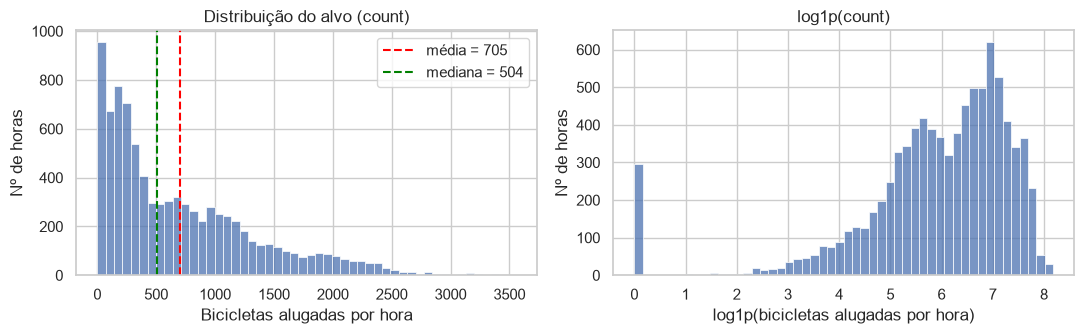

Nº de linhas (horas): 8760
Mínimo: 0
Máximo: 3556
Média: 704.6
Mediana: 504.5
Largura de cada caixa (bins=50): 71.12
Linhas com count == 0: 295
Total de bicicletas alugadas: 6172314


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

sns.histplot(df["count"], bins=50, ax=ax[0])
ax[0].set_title("Distribuição do alvo (count)")
ax[0].set_xlabel("Bicicletas alugadas por hora")
ax[0].set_ylabel("Nº de horas")
# linhas verticais com a média e a mediana
ax[0].axvline(df["count"].mean(), color="red", linestyle="--", label=f"média = {df['count'].mean():.0f}")
ax[0].axvline(df["count"].median(), color="green", linestyle="--", label=f"mediana = {df['count'].median():.0f}")
ax[0].legend()

sns.histplot(np.log1p(df["count"]), bins=50, ax=ax[1])
ax[1].set_title("log1p(count)")
ax[1].set_xlabel("log1p(bicicletas alugadas por hora)")
ax[1].set_ylabel("Nº de horas")

plt.tight_layout(); plt.show()

# valores resumidos do alvo
print("Nº de linhas (horas):", len(df))
print("Mínimo:", df["count"].min())
print("Máximo:", df["count"].max())
print("Média: %.1f" % df["count"].mean())
print("Mediana:", df["count"].median())
print("Largura de cada caixa (bins=50): %.2f" % ((df["count"].max() - df["count"].min()) / 50))
print("Linhas com count == 0:", (df["count"] == 0).sum())
print("Total de bicicletas alugadas:", df["count"].sum())

| Valor no Eixo X (log1p) | Fórmula de Reversão | Bicicletas Reais (aprox.) |
| :---: | :---: | :---: |
| **0** | $e^0 - 1 = 1 - 1$ | **0** |
| **1** | $e^1 - 1 \approx 2{,}72 - 1$ | **~2** |
| **2** | $e^2 - 1 \approx 7{,}39 - 1$ | **~6** |
| **3** | $e^3 - 1 \approx 20{,}09 - 1$ | **~19** |
| **4** | $e^4 - 1 \approx 54{,}60 - 1$ | **~54** |
| **5** | $e^5 - 1 \approx 148{,}41 - 1$ | **~147** |
| **6** | $e^6 - 1 \approx 403{,}43 - 1$ | **~402** |
| **7** | $e^7 - 1 \approx 1096{,}63 - 1$ | **~1096** |
| **8** | $e^8 - 1 \approx 2980{,}96 - 1$ | **~2980** |
| **8.17** | $e^{8{,}176} - 1$ | **3556 (máximo)** |

**Como ler.** Cada barra conta quantas horas tiveram aquela procura.

- **Esquerda:** na maioria das horas alugam-se poucas bicicletas, e só em poucas horas se alugam muitas (até cerca de 3500). Por isso o gráfico começa alto e vai descendo.
- **Direita:** aplicámos o logaritmo (`log1p`) só para "encolher" os valores grandes e ver melhor a forma dos dados. Fica mais equilibrado.
- **Barra isolada em 0:** são as **295 horas em que o sistema estava parado**. Não é procura baixa, é serviço indisponível. Tratamo-las na secção seguinte.

## 3. Limpeza: Remoção de `Functioning Day = No`
Quando o sistema está parado a procura é sempre 0. Isso não é "procura baixa", é "serviço indisponível", e não depende da hora, da temperatura nem da estação. Se ficasse, o modelo tentaria explicar zeros que as variáveis não explicam. Verificamos primeiro e removemos depois.

In [5]:
print(df.groupby("functioning")["count"].agg(["count", "sum", "mean"]))
print("\nLinhas com count==0 em dias a funcionar:", ((df["count"] == 0) & (df["functioning"] == "Yes")).sum())
df = df[df["functioning"] == "Yes"].copy()
print("Dimensão após remover dias sem funcionamento:", df.shape)

             count      sum        mean
functioning                            
No             295        0    0.000000
Yes           8465  6172314  729.156999

Linhas com count==0 em dias a funcionar: 0
Dimensão após remover dias sem funcionamento: (8465, 14)


**Como ler.** As 295 linhas com `functioning = No` somam exatamente 0 bicicletas, e nenhuma hora de um dia a funcionar tem procura nula. Ficamos com 8465 linhas.

## 4. Engenharia de Variáveis (Features)
| Decisão | Motivo |
|---|---|
| `date` → `month`, `dayofweek`, `is_weekend` | Um modelo não usa texto de data; estas variáveis captam sazonalidade e padrão semanal. |
| `hour` → `hour_sin`, `hour_cos` (mantém-se também `hour`) | A hora é cíclica (23h está perto de 0h). As árvores podem usar `hour` diretamente; os modelos lineares beneficiam de seno/cosseno. |
| `season` → one-hot | Categórica sem ordem. |
| `holiday` → 0/1 | Binária. |
| `functioning` → removida | Passou a ser constante (só "Yes"). |

In [6]:
# Só transforma se ainda não foi transformado (a coluna 'season' deixa de existir depois do one-hot).
if "season" not in df.columns:
    print(" Esta célula já foi executada: os dados não foram alterados. Para recomeçar, faz Restart + Run All.")
else:
    # 1) Data -> timestamp. A data vem como texto "dd/mm/aaaa"; juntamos a hora para ter um
    #    instante no tempo e conseguir ordenar cronologicamente (essencial para o split temporal).
    df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y")
    df["datetime"] = df["date"] + pd.to_timedelta(df["hour"], unit="h")
    df = df.sort_values("datetime").reset_index(drop=True)
    assert df["datetime"].is_monotonic_increasing and df["datetime"].is_unique   # ordem e sem duplicados

    # 2) Variáveis de calendário extraídas da data
    df["month"] = df["date"].dt.month                       # 1 a 12 (sazonalidade)
    df["dayofweek"] = df["date"].dt.dayofweek               # 0 = segunda ... 6 = domingo
    df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)   # 1 = sábado ou domingo

    # 3) Hora cíclica: ponto num círculo de 24 h (23h fica perto de 0h)
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

    # 4) Variáveis categóricas -> números
    df["holiday"] = (df["holiday"] == "Holiday").astype(int)                  # 1 = feriado
    df = pd.get_dummies(df, columns=["season"], prefix="season", dtype=int)   # one-hot (sem ordem)

# 5) Alvo e lista de variáveis de entrada
TARGET = "count"
FEATURES = [c for c in df.columns if c not in [TARGET, "date", "datetime", "functioning"]]
# colunas numéricas contínuas (as únicas que precisam de normalização)
NUM_COLS = ["temp", "humidity", "wind", "visibility", "dew_point", "solar", "rain", "snow"]

# 6) Verificações rápidas
assert df[FEATURES + [TARGET]].isna().sum().sum() == 0, "há valores em falta"
assert df[FEATURES].select_dtypes(exclude="number").empty, "há colunas que não são numéricas"
assert df["holiday"].isin([0, 1]).all() and df["holiday"].sum() > 0, "holiday está errado"
print("Nº de variáveis:", len(FEATURES))
print("Período:", df["datetime"].min(), "→", df["datetime"].max())
print("Features:", FEATURES)
df[FEATURES + [TARGET]].head()
df[["season_Autumn", "season_Spring", "season_Summer", "season_Winter"]].sum()

Nº de variáveis: 19
Período: 2017-12-01 00:00:00 → 2018-11-30 23:00:00
Features: ['hour', 'temp', 'humidity', 'wind', 'visibility', 'dew_point', 'solar', 'rain', 'snow', 'holiday', 'month', 'dayofweek', 'is_weekend', 'hour_sin', 'hour_cos', 'season_Autumn', 'season_Spring', 'season_Summer', 'season_Winter']


season_Autumn    1937
season_Spring    2160
season_Summer    2208
season_Winter    2160
dtype: int64

**Como ler.** Esta célula prepara as colunas para os modelos, que só trabalham com números.

- **Data → timestamp e ordenação.** Juntamos a data e a hora num único instante (`datetime`) e ordenamos as linhas no tempo. Sem isto não podíamos fazer a divisão cronológica da secção 5.
- **Calendário.** Da data tiramos o `month`, o `dayofweek` e o `is_weekend`. Servem para o modelo perceber a época do ano e a diferença entre dias úteis e fim de semana.
- **Hora em seno e cosseno.** A hora é cíclica: 23h está perto de 0h. Com seno e cosseno cada hora passa a ser um ponto num círculo, e a distância entre 23h e 0h fica pequena. Mantemos também `hour` para as árvores.
- **Categorias → números.** `holiday` passa a 0/1. `season` passa a uma coluna por estação (one-hot), porque as estações não têm ordem.
- **`FEATURES`, `TARGET` e `NUM_COLS`.** `TARGET` é o que queremos prever (`count`). `FEATURES` são as 19 colunas de entrada. `NUM_COLS` são as numéricas contínuas, as únicas que serão normalizadas.
- **Verificações.** Confirmamos que os dados estão ordenados, sem duplicados, sem valores em falta e todos numéricos.

**A tabela no fim** mostra as primeiras linhas já transformadas, para confirmar o resultado.

### 4.1 Que variáveis pesam mais na procura?
Antes de modelar, medimos quanto cada variável se relaciona com o número de bicicletas alugadas. Esta análise é **descritiva**: mostra o que os dados dizem e não substitui a comparação de modelos das secções seguintes.

**Como ler a primeira tabela (correlação com `count`).** Vai de −1 a 1. Quanto mais longe de 0, mais a variável acompanha a procura; o sinal diz se sobe (+) ou desce (−) com ela.
- A **temperatura** é a mais correlacionada (0,56): com mais calor, mais bicicletas.
- Segue-se a **hora** (0,43). Esta correlação subestima a sua importância, porque a relação tem dois picos (8h e 18h) e não é uma reta.
- O **ponto de orvalho** (0,40) quase repete a temperatura, por isso não traz informação nova.
- Humidade, chuva, neve, vento, feriado e dia da semana têm correlações fracas (entre −0,20 e 0,13).

In [7]:
# Correlação de cada variável com o alvo (ordenada pela força, sem olhar ao sinal)
cols = ["temp", "hour", "dew_point", "solar", "humidity", "month", "wind", "rain", "snow", "holiday", "dayofweek"]
tab_corr = df[cols].corrwith(df["count"]).sort_values(key=abs, ascending=False).round(3).to_frame("correlação com count")
display(tab_corr)

# Estação do ano: temperatura média e procura média (a estação está em 4 colunas one-hot)
estacao = df[["season_Autumn", "season_Spring", "season_Summer", "season_Winter"]].idxmax(axis=1).str.replace("season_", "")
tab_est = df.groupby(estacao).agg(horas=("count", "size"), temp_media=("temp", "mean"), procura_media=("count", "mean")).round(1)
display(tab_est)

# Quanto da variação da procura a estação explica sozinha (eta²) vs. a temperatura (r²)
g = df.groupby(estacao)["count"]
eta2 = 1 - sum(((x - x.mean())**2).sum() for _, x in g) / ((df["count"] - df["count"].mean())**2).sum()
print("Estação explica %.1f%% da variação da procura | temperatura (linear) explica %.1f%%" % (100*eta2, 100*df["temp"].corr(df["count"])**2))

,correlação com count
temp,0.563
hour,0.425
dew_point,0.400
solar,0.274
humidity,-0.202
month,0.167
snow,-0.152
rain,-0.129
wind,0.125
holiday,-0.070


,horas,temp_media,procura_media
Autumn,1937,13.8,924.1
Spring,2160,13.0,746.3
Summer,2208,26.6,1034.1
Winter,2160,-2.5,225.5


Estação explica 23.7% da variação da procura | temperatura (linear) explica 31.7%


## 5. Split Cronológico (80% Treino / 20% Teste) e TimeSeriesSplit
**Porque não um split aleatório.** Os dados são uma série temporal horária, e horas vizinhas são muito parecidas. Num split aleatório, a hora das 14h ficaria no treino e a das 15h no teste. O modelo "espreitaria" o teste e as métricas ficariam otimistas (**fuga de informação**). Por isso treinamos no passado e testamos no futuro.

**O que fazemos.**
- **Treino:** as primeiras 80% das horas (6772), de 1 de dezembro de 2017 a 11 de setembro de 2018.
- **Teste:** as últimas 20% (1693), de 11 de setembro a 30 de novembro de 2018. Só o usamos no fim, para medir.
- **Validação cruzada:** usamos `TimeSeriesSplit` com 5 folds, só dentro do treino. Em cada fold o modelo treina em dados mais antigos e valida em dados mais recentes. É com isto que escolhemos parâmetros e comparamos modelos, sem tocar no teste.

**Como funciona o `TimeSeriesSplit` (5 folds), dentro do treino (6772 horas).** O treino divide-se em 6 blocos seguidos no tempo, de cerca de 1128 horas cada (o primeiro tem 1132). Em cada fold, o modelo treina nos blocos mais antigos e valida no bloco seguinte.

| Fold | Treina com | Valida em | Nº de horas (treino / validação) |
|---|---|---|---|
| 1 | bloco 1 | bloco 2 | 1132 / 1128 |
| 2 | blocos 1–2 | bloco 3 | 2260 / 1128 |
| 3 | blocos 1–3 | bloco 4 | 3388 / 1128 |
| 4 | blocos 1–4 | bloco 5 | 4516 / 1128 |
| 5 | blocos 1–5 | bloco 6 | 5644 / 1128 |

O treino cresce em cada fold, mas a validação vem **sempre depois** dos dados de treino. O resultado final de cada modelo (`CV_RMSE`, etc.) é a média dos 5 folds.


In [8]:
n_test = int(len(df) * TEST_FRAC)
train, test = df.iloc[:-n_test], df.iloc[-n_test:]

X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

tscv = TimeSeriesSplit(n_splits=5)   # validação cruzada temporal, usada em todos os GridSearchCV

resumo = pd.DataFrame({
    "Linhas": [len(train), len(test)],
    "Início": [train["datetime"].min().date(), test["datetime"].min().date()],
    "Fim": [train["datetime"].max().date(), test["datetime"].max().date()],
    "Média do alvo": [y_train.mean().round(1), y_test.mean().round(1)],
    "Mediana do alvo": [y_train.median(), y_test.median()],
    "Temperatura média (°C)": [train["temp"].mean().round(1), test["temp"].mean().round(1)],
    "Horas de outono": [int(train["season_Autumn"].sum()), int(test["season_Autumn"].sum())],
}, index=["Treino", "Teste"]).T
resumo

,Treino,Teste
Linhas,6772,1693
Início,2017-12-01,2018-09-11
Fim,2018-09-11,2018-11-30
Média do alvo,687.5,895.6
Mediana do alvo,444.0,835.0
Temperatura média (°C),12.9,12.4
Horas de outono,244,1693


## 6. Função de Avaliação Global (MAE, RMSE, R²)
Esta secção prepara a infraestrutura para treinar e avaliar todos os modelos de forma consistente e comparável:

* **Métricas Principais:**
  * **MAE (Mean Absolute Error):** Erro médio absoluto em bicicletas/hora. É fácil de interpretar no contexto real do negócio e menos sensível a outliers.
  * **RMSE (Root Mean Squared Error):** Erro quadrático médio. Penaliza com muito mais severidade os erros grandes (falhar a previsão numa hora de ponta tem um custo operacional elevado).
  * **R² (Coeficiente de Determinação):** Percentagem da variabilidade dos dados que o modelo consegue explicar. Serve para comparar diretamente com a previsão ingénua da média (baseline).

* **Pipeline e Prevenção de Data Leakage:**
  * A função `make_preprocessor()` aplica `StandardScaler` apenas às colunas numéricas contínuas. Ao integrá-la num `Pipeline`, garantimos que a normalização é ajustada estritamente com os dados de treino de cada divisão temporal (*fold*), prevenindo fuga de informação do teste para o treino.

* **Funções Auxiliares:**
  * `avaliar()`: Treina o estimador, faz previsões no teste, calcula as métricas no teste e executa validação cruzada temporal (`TimeSeriesSplit`) no conjunto de treino. Se for pedido `log_target=True`, aplica `log1p` no treino e reverte com `expm1` nas previsões.
  * `tabela_resultados()`: Compila e resume as métricas acumuladas de todos os modelos avaliados para facilitar a comparação final.

In [9]:
def make_preprocessor(scale=True):
    # Se scale=False (ex.: árvores), passa as colunas sem alterar
    if not scale:
        return "passthrough"
    # Normaliza apenas NUM_COLS e mantém o resto inalterado
    return ColumnTransformer([("num", StandardScaler(), NUM_COLS)], remainder="passthrough")

RESULTADOS = [] # Acumula as métricas de cada modelo

def avaliar(modelo, nome, X_tr=None, y_tr=None, X_te=None, y_te=None, cv=True, log_target=False):
    # Usa variáveis de treino/teste padrão se não forem passadas
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    X_te = X_test if X_te is None else X_te
    y_te = y_test if y_te is None else y_te

    # Aplica log1p ao target se solicitado
    y_fit = np.log1p(y_tr) if log_target else y_tr
    modelo.fit(X_tr, y_fit)
    pred = modelo.predict(X_te)
    
    # Reverte o log e impede valores negativos
    if log_target:
        pred = np.expm1(pred)
    pred = np.clip(pred, 0, None)

    # Métricas no conjunto de teste
    linha = {
        "modelo": nome,
        "MAE": mean_absolute_error(y_te, pred),
        "RMSE": np.sqrt(mean_squared_error(y_te, pred)),
        "R2": r2_score(y_te, pred)
    }

    # Validação cruzada temporal no treino (apenas sem log)
    if cv and not log_target:
        s = cross_validate(modelo, X_tr, y_tr, cv=tscv,
                           scoring=("neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"))
        linha.update({
            "CV_MAE": -s["test_neg_mean_absolute_error"].mean(),
            "CV_RMSE": -s["test_neg_root_mean_squared_error"].mean(),
            "CV_R2": s["test_r2"].mean()
        })

    # Guarda o resultado e devolve a linha em DataFrame junto com as previsões
    RESULTADOS.append(linha)
    return pd.DataFrame([linha]).round(3), pred

def tabela_resultados():
    # Junta os resultados, remove execuções antigas do mesmo modelo e indexa pelo nome
    return pd.DataFrame(RESULTADOS).drop_duplicates("modelo", keep="last").set_index("modelo").round(3)

## 7. Baselines
### 7.1 Baseline: DummyRegressor (previsão da média)
Prevê sempre a média do treino. É o "piso": qualquer modelo tem de o superar. No teste o R² é negativo porque a média do treino (≈688) é inferior à do teste (≈896).

In [10]:
r, _ = avaliar(DummyRegressor(strategy="mean"), "Baseline: média")
r

,modelo,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
0,Baseline: média,491.506,634.409,-0.12,510.389,676.52,-0.466


**Como ler os resultados (Baseline: média):**

* **O que faz:** Não usa variáveis meteorológicas nem horas; prevê sempre a média do treino ($\approx 688$ bicicletas/hora) para qualquer situação futura.

* **Métricas no Teste:**
  * **MAE (491.506):** Erro médio de quase 500 bicicletas a cada hora face ao valor real.
  * **RMSE (634.409):** Muito superior ao MAE porque penaliza fortemente os erros graves nas horas de ponta (onde prever 688 falha por milhares de bicicletas).
  * **R² (-0.120):** Não explica qualquer padrão e fica negativo porque a procura média no teste (outono, $\approx 896$) foi muito superior à média histórica do treino ($\approx 688$).

* **Validação Cruzada (CV_):**
  * **CV_MAE (510.389) e CV_RMSE (676.520):** Mostram que o erro de ~500 bicicletas se mantém ao longo das várias fases do ano.
  * **CV_R² (-0.466):** Confirma que projetar a média do passado falha sempre devido às mudanças de estação.

* **Conclusão:** É a referência mínima obrigatória (*baseline* / "piso"). Qualquer modelo real (como Árvores ou Regressão) só tem valor útil se apresentar erros bem mais baixos que estes e um $R^2$ positivo.

### 7.2 Regressão linear simples (referência)
Serve de ponto de comparação para os modelos lineares mais complexos (secções 9 a 12) e para os modelos não lineares (Parte III).

,modelo,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
0,Regressão linear (baseline),324.292,428.833,0.488,398.771,501.446,0.154


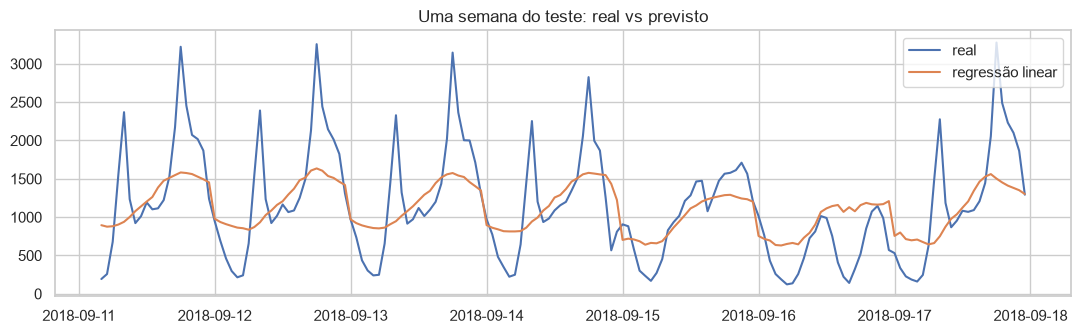

In [11]:
lin = Pipeline([("prep", make_preprocessor(scale=True)), ("modelo", LinearRegression())])
r, pred_lin = avaliar(lin, "Regressão linear (baseline)")
display(r)

# Previsto vs real numa semana do conjunto de teste
sem = test["datetime"] < test["datetime"].min() + pd.Timedelta(days=7)
plt.figure(figsize=(11, 3.5))
plt.plot(test.loc[sem, "datetime"], y_test[sem], label="real")
plt.plot(test.loc[sem, "datetime"], pred_lin[sem.values], label="regressão linear")
plt.legend(); plt.title("Uma semana do teste: real vs previsto"); plt.tight_layout(); plt.show()

**Como ler.** A linha azul é a procura real e a laranja a previsão da regressão linear. A linha reta não consegue reproduzir os picos das 8h e das 18h (reais ~3000, previstos ~1600) e prevê procura a mais de madrugada. É a razão para testar modelos não lineares.

# PARTE II — EXPLORAÇÃO DETALHADA E MODELOS LINEARES

## 8. Exploração detalhada dos dados
Antes de modelar, exploramos o comportamento da procura: distribuição do alvo, padrão por hora (dias úteis e fins de semana), estação do ano, temperatura, correlações e colinearidade entre as variáveis meteorológicas.

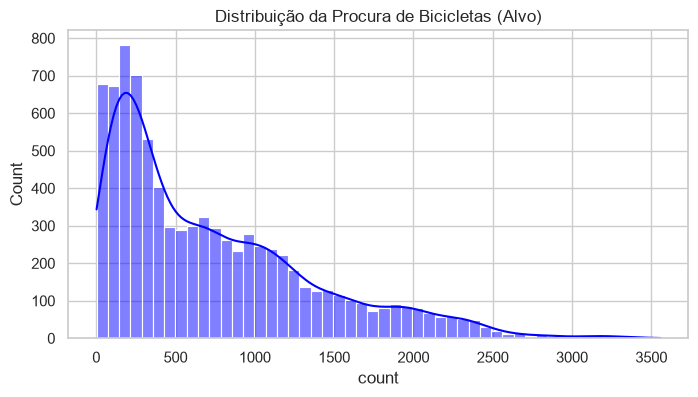

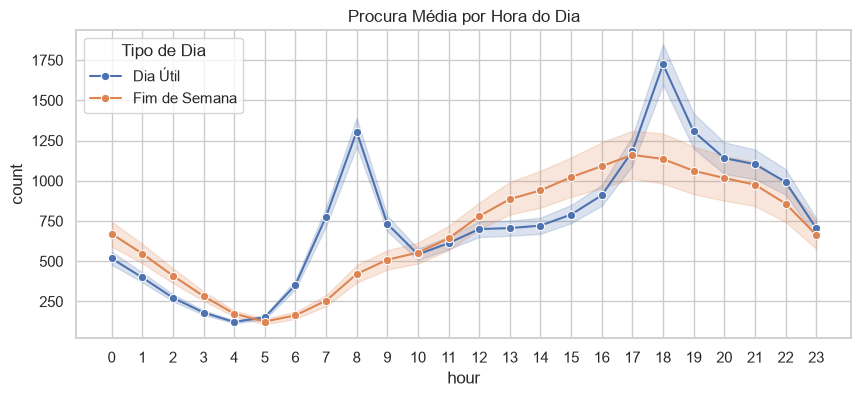

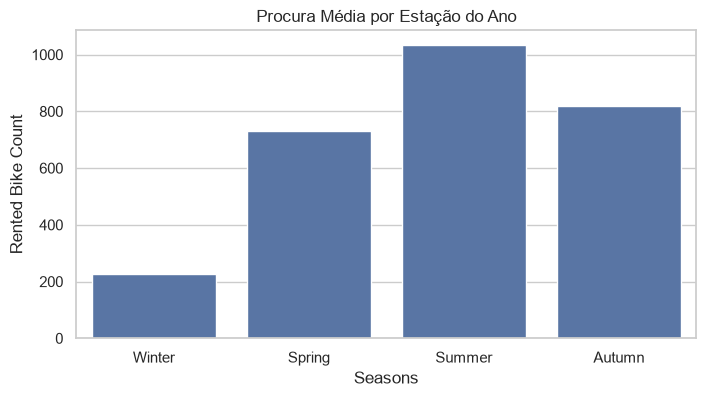

In [12]:
# 1. Distribuição do Alvo (Histograma)
plt.figure(figsize=(8, 4))
sns.histplot(df["count"], bins=50, kde=True, color="blue")
plt.title("Distribuição da Procura de Bicicletas (Alvo)")
plt.show()

# 2. Procura Média por Hora (Dia Útil vs Fim de Semana)
plt.figure(figsize=(10, 4))
df_plot = df.copy()
df_plot["Tipo de Dia"] = df_plot["is_weekend"].map({0: "Dia Útil", 1: "Fim de Semana"})
sns.lineplot(data=df_plot, x="hour", y="count", hue="Tipo de Dia", marker="o")
plt.title("Procura Média por Hora do Dia")
plt.xticks(range(0, 24))
plt.show()

# 3. Procura por Estação do Ano
plt.figure(figsize=(8, 4))
sns.barplot(data=df_raw, x="Seasons", y="Rented Bike Count", errorbar=None)
plt.title("Procura Média por Estação do Ano")
plt.show()

### 8.1 Alvo, hora do dia e estação do ano
**Alvo.** Representámos a distribuição do número de bicicletas alugadas por hora. O histograma mostra assimetria positiva: a maior parte das horas tem procura baixa, com uma cauda longa de valores elevados. Esta assimetria justifica testar uma transformação logarítmica do alvo e antecipa que os maiores erros dos modelos ocorrerão nas horas de pico.

**Hora do dia.** Calculámos a procura média por hora, separando dias úteis de fins de semana. Nos dias úteis há dois picos, às 8h e às 18h, coincidentes com as deslocações casa-trabalho ou escola, enquanto ao fim de semana existe um único pico ao fim da tarde. A relação com a hora é, portanto, não monótona e depende do tipo de dia, pelo que uma regressão linear com a hora como variável numérica não a consegue captar. Isto justifica o uso de termos polinomiais e da variável de fim de semana.

**Estação do ano.** Comparámos a procura média por estação. O verão regista a procura mais elevada, seguido do outono e da primavera, e o inverno apresenta uma quebra acentuada, com uma média cerca de cinco vezes inferior à do verão. A estação tem assim forte poder explicativo e deve entrar nos modelos como variável categórica (one-hot).

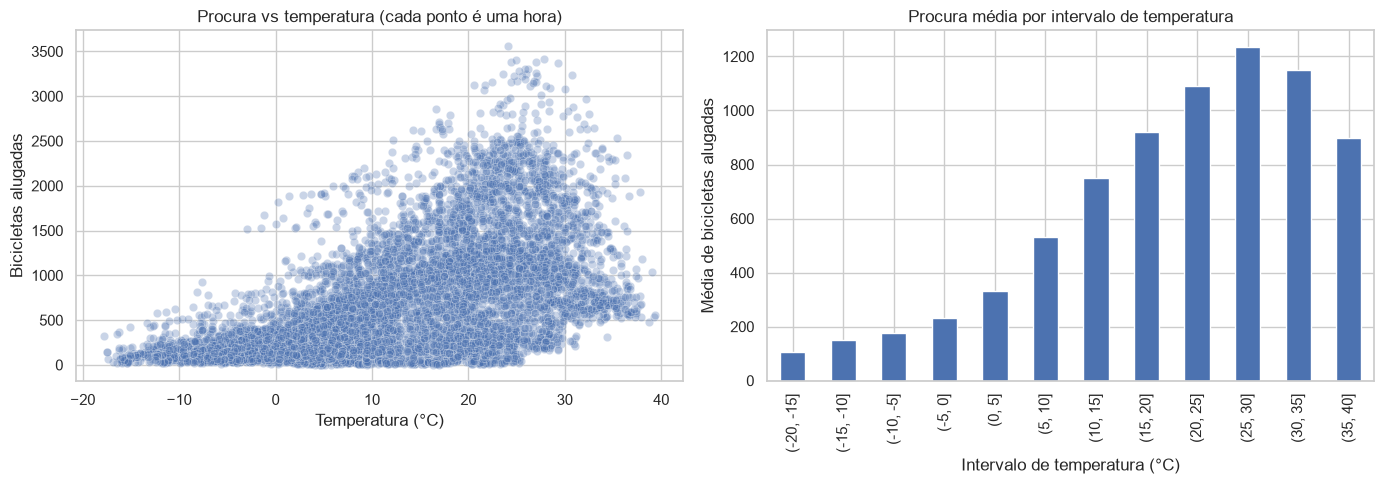

temp
(-20, -15]     105
(-15, -10]     151
(-10, -5]      177
(-5, 0]        232
(0, 5]         330
(5, 10]        531
(10, 15]       750
(15, 20]       919
(20, 25]      1089
(25, 30]      1235
(30, 35]      1150
(35, 40]       900


In [13]:
# Procura vs temperatura: pontos (cada ponto é uma hora) e média por intervalo de 5 °C
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x="temp", y="count", alpha=0.3, ax=axes[0])
axes[0].set_title("Procura vs temperatura (cada ponto é uma hora)")
axes[0].set_xlabel("Temperatura (°C)"); axes[0].set_ylabel("Bicicletas alugadas")

faixa = pd.cut(df["temp"], bins=range(-20, 45, 5))
media_faixa = df.groupby(faixa, observed=True)["count"].mean()
media_faixa.plot(kind="bar", ax=axes[1])
axes[1].set_title("Procura média por intervalo de temperatura")
axes[1].set_xlabel("Intervalo de temperatura (°C)"); axes[1].set_ylabel("Média de bicicletas alugadas")

plt.tight_layout(); plt.show()
print(media_faixa.round(0).astype(int).to_string())

### 8.2 Procura vs temperatura
Representámos a procura em função da temperatura, com um ponto por hora e com a média por intervalos de 5 °C. A procura aumenta com a temperatura: abaixo de 0 °C a média ronda as 100 a 330 bicicletas por hora, e atinge o máximo no intervalo entre 25 e 30 °C (1235). A partir daí desce, para 1150 entre 30 e 35 °C e 900 entre 35 e 40 °C, o que indica que o calor extremo desincentiva a utilização. A nuvem de pontos é muito dispersa, pelo que a temperatura sozinha não explica a procura e as outras variáveis (hora, chuva, estação) também contribuem. A forma de "montanha" mostra que a relação não é linear, o que justifica o uso de um polinómio na temperatura.

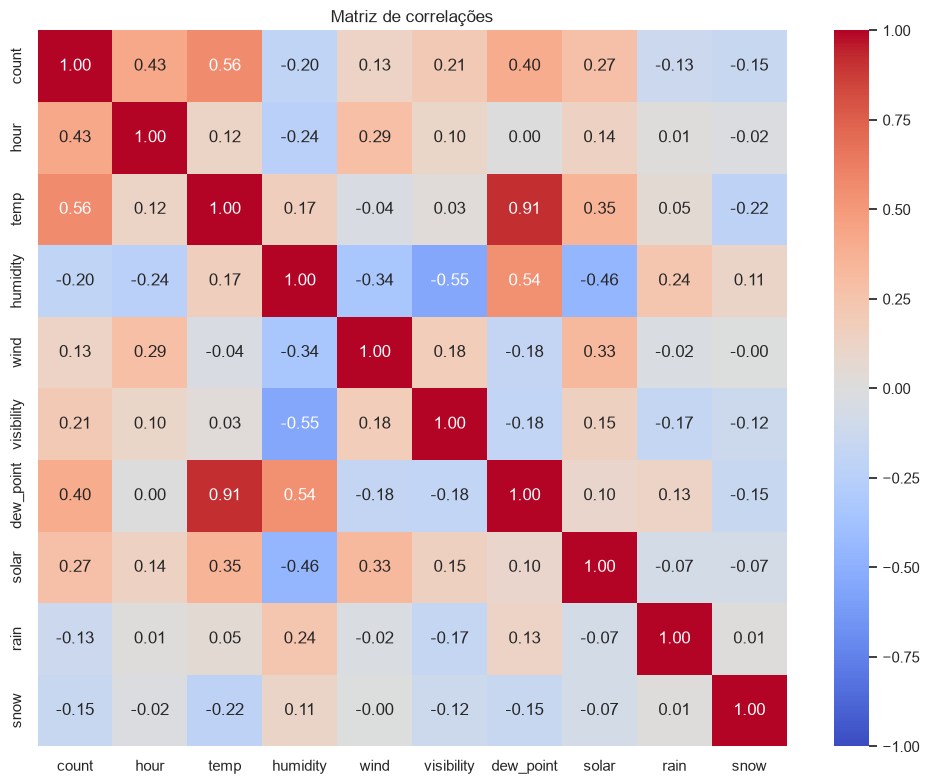

Correlação temp vs dew_point: 0.91
Correlação humidity vs dew_point: 0.54
Correlação temp vs count: 0.56


In [14]:
# Matriz de correlações entre o alvo e as variáveis numéricas
colunas_corr = ["count", "hour", "temp", "humidity", "wind", "visibility",
                "dew_point", "solar", "rain", "snow"]
corr = df[colunas_corr].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlações")
plt.tight_layout(); plt.show()

print("Correlação temp vs dew_point:", round(df["temp"].corr(df["dew_point"]), 2))
print("Correlação humidity vs dew_point:", round(df["humidity"].corr(df["dew_point"]), 2))
print("Correlação temp vs count:", round(df["temp"].corr(df["count"]), 2))

### 8.3 Matriz de correlações
Calculámos a matriz de correlações entre o alvo e as variáveis numéricas. As variáveis mais correlacionadas com a procura são a temperatura (0,56), a hora (0,43) e o ponto de orvalho (0,40), enquanto a humidade, a chuva e a neve têm correlação negativa e fraca. A correlação da hora é apenas moderada porque a relação com a procura não é linear (tem dois picos ao longo do dia) e a correlação de Pearson só mede relações lineares. O resultado mais relevante é a correlação de 0,91 entre a temperatura e o ponto de orvalho, ou seja, as duas variáveis transportam quase a mesma informação. Esta multicolinearidade pode tornar instáveis os coeficientes de uma regressão linear, e é a razão pela qual testamos o Ridge e o Lasso na secção 9. Há também correlações moderadas entre a humidade e a visibilidade (−0,55), o ponto de orvalho (0,54) e a radiação solar (−0,46).

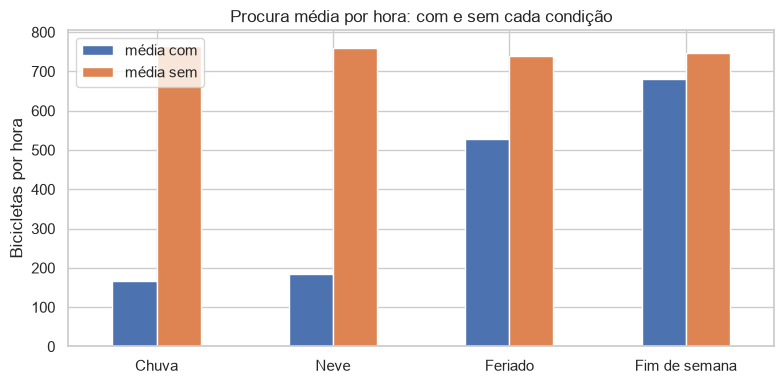

,média com,média sem,nº de horas com,diferença (%)
Chuva,167,766,516,-78
Neve,185,759,443,-76
Feriado,529,739,408,-28
Fim de semana,682,748,2441,-9


In [15]:
# Efeito bruto de chuva, neve, feriado e fim de semana na procura média por hora
grupos = {
    "Chuva":         df["rain"] > 0,
    "Neve":          df["snow"] > 0,
    "Feriado":       df["holiday"] == 1,
    "Fim de semana": df["is_weekend"] == 1,
}
efeitos = pd.DataFrame({
    nome: {"média com": df.loc[m, "count"].mean(),
           "média sem": df.loc[~m, "count"].mean(),
           "nº de horas com": int(m.sum())}
    for nome, m in grupos.items()}).T
efeitos["diferença (%)"] = (efeitos["média com"] / efeitos["média sem"] - 1) * 100
efeitos = efeitos.round(0).astype(int)

efeitos[["média com", "média sem"]].plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("Procura média por hora: com e sem cada condição")
plt.ylabel("Bicicletas por hora"); plt.tight_layout(); plt.show()
efeitos

### 8.4 Efeito da chuva, da neve, do feriado e do fim de semana
Calculámos a procura média por hora nas horas com e sem chuva, com e sem neve, em feriado e em fim de semana. A procura cai de forma muito marcada com chuva (167 contra 766 bicicletas por hora, −78%) e com neve (185 contra 759, −76%), enquanto o feriado (529 contra 739, −28%) e o fim de semana (682 contra 748, −9%) têm um efeito bem menor. São diferenças brutas, que misturam outros fatores (por exemplo, a neve ocorre sobretudo no inverno, quando a procura já é baixa), mas mostram que `rain` e `snow` transportam informação útil apesar de serem nulas em cerca de 94% das horas. Os feriados são apenas 408 horas, pelo que o modelo dispõe de pouca informação para aprender esse efeito.

In [16]:
# VIF (fator de inflação da variância) das variáveis contínuas: acima de 10 indica colinearidade grave
Z = (df[NUM_COLS] - df[NUM_COLS].mean()) / df[NUM_COLS].std()
vif = {}
for col in NUM_COLS:
    resto = [c for c in NUM_COLS if c != col]
    r2 = LinearRegression().fit(Z[resto], Z[col]).score(Z[resto], Z[col])   # quanto as outras explicam esta variável
    vif[col] = 1 / (1 - r2)
vif = pd.Series(vif, name="VIF").sort_values(ascending=False).round(1)
vif.to_frame()

,VIF
dew_point,116.2
temp,87.2
humidity,20.1
solar,2.0
visibility,1.6
wind,1.2
snow,1.1
rain,1.1


### 8.5 Colinearidade: VIF
Para quantificar a colinearidade calculámos o VIF (fator de inflação da variância) de cada variável contínua, que mede quanto a variância do coeficiente aumenta por as restantes variáveis a explicarem. O `dew_point` (116) e a `temp` (87) têm valores muito acima de 10, o limiar habitual de colinearidade grave, e a `humidity` (20) também o ultrapassa; as restantes ficam abaixo de 2. Isto confirma, para além da correlação de 0,91, que estas três variáveis se explicam mutuamente (o ponto de orvalho é calculado a partir da temperatura e da humidade) e justifica o uso de regularização (Ridge e Lasso) na secção 9.

## Modelos lineares (secções 9 a 12)
Esta secção avalia modelos lineares de complexidade crescente: regressão polinomial em temperatura e hora, Ridge (penalização L2) e Lasso (penalização L1). A motivação é dupla. Por um lado, a regressão linear simples não capta a forma não linear da procura ao longo do dia e com a temperatura; por outro, a correlação elevada entre temperatura e ponto de orvalho (≈ 0,9) pode tornar os coeficientes instáveis. O grau do polinómio e o α são escolhidos por `GridSearchCV` com validação cruzada temporal (`tscv`), partindo do mesmo split e da mesma função de avaliação da secção 6, para que os resultados sejam comparáveis com os dos restantes modelos.

Índice: 9. Regressão polinomial · 10. Ridge · 11. Lasso · 12. Resultados, coeficientes e hora categórica

## 9. Regressão polinomial em temperatura e hora
Aplicámos `PolynomialFeatures` apenas a `temp` e `hour`, as duas variáveis cuja relação com a procura não é linear, mantendo as restantes como no baseline. Desta forma limita-se o número de colunas e facilita-se a interpretação do modelo. A temperatura e a hora são normalizadas antes de serem elevadas a potências, dentro do `Pipeline`, para que o scaler aprenda apenas com os dados de treino de cada fold. Treinámos os graus 1 a 5 com regressão linear sem regularização, para isolar o efeito do grau e observar o sobreajuste.

In [17]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


def make_prep_poly(degree):
  """Polinómio de grau `degree` só em temp e hour; o resto como no baseline.

  Usar dentro de Pipeline (o scaler é ajustado só nos dados de treino de cada
  fold).
  """
  poly = Pipeline([
      ("sc", StandardScaler()),
      ("pf", PolynomialFeatures(degree=degree, include_bias=False)),
  ])
  outras = [c for c in NUM_COLS if c != "temp"] + [
      "month",
      "dayofweek",
      "hour_sin",
      "hour_cos",
  ]
  return ColumnTransformer(
      [
          ("poly", poly, ["temp", "hour"]),
          ("num", StandardScaler(), outras),
      ],
      remainder="passthrough",  # binárias: feriado, fim de semana, estações
  )


linhas = []
for d in [1, 2, 3, 4, 5]:
  m = Pipeline([("prep", make_prep_poly(d)), ("modelo", LinearRegression())])
  r, _ = avaliar(m, f"Polinómio grau {d} (temp, hora)")

  # Número de colunas após a expansão polinomial
  n_cols = m.named_steps["prep"].transform(X_train).shape[1]

  # Previsões no conjunto de treino com corte em zero para valores negativos
  pred_tr = np.clip(m.predict(X_train), 0, None)

  # Métricas no conjunto de treino
  rmse_treino = np.sqrt(mean_squared_error(y_train, pred_tr))
  r2_treino = r2_score(y_train, pred_tr)

  # Construção da linha com todas as métricas comparativas
  linhas.append({
      "grau": d,
      "RMSE treino": rmse_treino,
      "RMSE teste": r["RMSE"].iloc[0],
      "CV_RMSE": r["CV_RMSE"].iloc[0],
      "R2 treino": r2_treino,
      "R2 teste": r["R2"].iloc[0],
      "CV_R2": r["CV_R2"].iloc[0],
  })

graus = pd.DataFrame(linhas).set_index("grau").round(3)
graus

,RMSE treino,RMSE teste,CV_RMSE,R2 treino,R2 teste,CV_R2
grau,,,,,,
1,422.645,428.833,501.446,0.572,0.488,0.154
2,394.559,433.703,469.636,0.627,0.476,0.231
3,344.092,389.743,407.358,0.716,0.577,0.424
4,328.151,379.648,416.170,0.742,0.599,0.371
5,314.958,364.623,493.122,0.762,0.630,-0.181


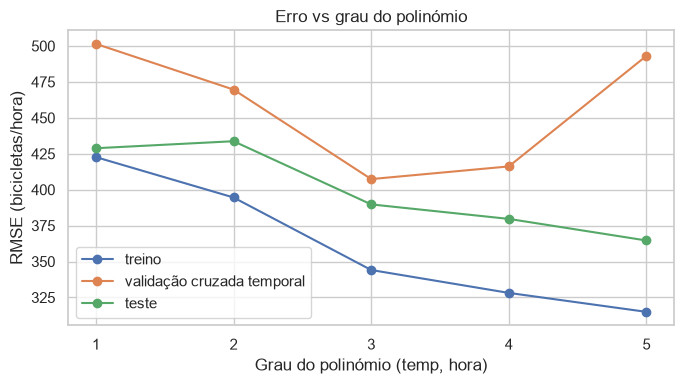

In [18]:
plt.figure(figsize=(7, 4))
for col, nome in [("RMSE treino", "treino"), ("CV_RMSE", "validação cruzada temporal"), ("RMSE teste", "teste")]:
    plt.plot(graus.index, graus[col], marker="o", label=nome)
plt.xlabel("Grau do polinómio (temp, hora)"); plt.ylabel("RMSE (bicicletas/hora)")
plt.xticks(graus.index); plt.legend(); plt.title("Erro vs grau do polinómio")
plt.tight_layout(); plt.show()

A tabela e o gráfico mostram que o grau 1 coincide com o baseline (R² de teste de 0,488) e que o grau 2 não traz melhoria (0,476). Este resultado é coerente com a forma bimodal da procura ao longo do dia, que uma parábola, com um só máximo, não consegue descrever. O grau 3 é o mais baixo que o faz: o RMSE de validação cruzada desce para 407 (contra 501 no baseline) e o R² de teste sobe para 0,577. A partir do grau 4, o erro de treino continua a diminuir (344 no grau 3 e 315 no grau 5), mas a validação cruzada deteriora-se e, no grau 5, torna-se instável (R² médio de −0,18), o que é sinal de sobreajuste. Embora o erro de teste continue a descer com o grau, este não pode ser escolhido com base no teste, sob pena de fuga de informação. Por isso, o grau é selecionado por validação cruzada na secção seguinte, onde se testam os graus 1 a 4.

## 10. Ridge com GridSearchCV
Combinámos o polinómio com a regressão Ridge, que é a resposta natural à colinearidade entre temperatura e ponto de orvalho por encolher os coeficientes sem os anular. Pesquisámos em simultâneo o grau (1 a 4) e o α (de 10⁻⁴ a 10⁴, em escala logarítmica), com validação cruzada temporal e o RMSE como critério, por estar expresso em bicicletas por hora e ser mais fácil de interpretar do que o R². A grelha de α é larga de propósito: se o melhor valor ficar no limite inferior, isso indica que a regularização não melhora o modelo.

In [19]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# 1. Pipeline (polinómio só em temperatura e hora; ver make_prep_poly na secção 9)
pipeline_ridge = Pipeline([
    ("prep", make_prep_poly(2)),
    ("modelo", Ridge(random_state=RANDOM_STATE))
])

# 2. Grelha de hiperparâmetros: grau do polinómio E alpha (escala logarítmica)
param_grid = {
    'prep__poly__pf__degree': [1, 2, 3, 4],
    'modelo__alpha': np.logspace(-4, 4, 17)
}

# 3. GridSearchCV com validação cruzada temporal (cv=tscv)
grid_search_ridge = GridSearchCV(
    estimator=pipeline_ridge,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

print("A treinar a Regressão Ridge Polinomial...")
grid_search_ridge.fit(X_train, y_train)

# 4. Avaliar e adicionar à tabela partilhada
melhor_grau = grid_search_ridge.best_params_['prep__poly__pf__degree']
melhor_alpha = grid_search_ridge.best_params_['modelo__alpha']
print(f"Melhor grau: {melhor_grau} | melhor alpha: {melhor_alpha:.4g} | CV_RMSE: {-grid_search_ridge.best_score_:.1f}")
r_ridge, pred_ridge = avaliar(grid_search_ridge.best_estimator_, f"Ridge poli (grau={melhor_grau}, alpha={melhor_alpha:.3g})")

# 5. Mostrar a tabela final atualizada com todos os modelos
tabela_resultados()

A treinar a Regressão Ridge Polinomial...
Melhor grau: 3 | melhor alpha: 0.0001 | CV_RMSE: 407.4


,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
modelo,,,,,,
Baseline: média,491.506,634.409,-0.120,510.389,676.520,-0.466
Regressão linear (baseline),324.292,428.833,0.488,398.771,501.446,0.154
"Polinómio grau 1 (temp, hora)",324.292,428.833,0.488,398.771,501.446,0.154
"Polinómio grau 2 (temp, hora)",345.348,433.703,0.476,363.755,469.636,0.231
"Polinómio grau 3 (temp, hora)",264.460,389.743,0.577,310.045,407.358,0.424
"Polinómio grau 4 (temp, hora)",260.319,379.648,0.599,297.659,416.170,0.371
"Polinómio grau 5 (temp, hora)",249.887,364.623,0.630,312.066,493.122,-0.181
"Ridge poli (grau=3, alpha=0.0001)",264.460,389.743,0.577,310.045,407.359,0.424


## 11. Lasso com GridSearchCV
Repetimos o procedimento com a regressão Lasso, cuja penalização L1 pode anular coeficientes e funciona como seleção de variáveis, o que permite comparar as duas formas de regularização. Usámos a mesma estrutura do Ridge, com o grau de 1 a 4 e o α de 10⁻³ a 10². O gráfico final mostra o erro de validação em função de α para cada grau.

In [20]:
import warnings
from sklearn.linear_model import Lasso
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # alphas muito pequenos convergem devagar

# 1. Pipeline
pipeline_lasso = Pipeline([
    ("prep", make_prep_poly(2)),
    ("modelo", Lasso(max_iter=20000, random_state=RANDOM_STATE))
])

# 2. Grelha de hiperparâmetros
param_grid_lasso = {
    'prep__poly__pf__degree': [1, 2, 3, 4],
    'modelo__alpha': np.logspace(-3, 2, 11)
}

# 3. GridSearchCV com validação cruzada temporal
grid_search_lasso = GridSearchCV(
    estimator=pipeline_lasso,
    param_grid=param_grid_lasso,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=1
)

print("A treinar a Regressão Lasso Polinomial...")
grid_search_lasso.fit(X_train, y_train)

# 4. Avaliar e adicionar à tabela partilhada
melhor_grau_l = grid_search_lasso.best_params_['prep__poly__pf__degree']
melhor_alpha_l = grid_search_lasso.best_params_['modelo__alpha']
print(f"Melhor grau: {melhor_grau_l} | melhor alpha: {melhor_alpha_l:.4g} | CV_RMSE: {-grid_search_lasso.best_score_:.1f}")
r_lasso, pred_lasso = avaliar(grid_search_lasso.best_estimator_, f"Lasso poli (grau={melhor_grau_l}, alpha={melhor_alpha_l:.3g})")

# 5. Tabela atualizada
tabela_resultados()

A treinar a Regressão Lasso Polinomial...
Melhor grau: 3 | melhor alpha: 0.001 | CV_RMSE: 408.5


,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
modelo,,,,,,
Baseline: média,491.506,634.409,-0.120,510.389,676.520,-0.466
Regressão linear (baseline),324.292,428.833,0.488,398.771,501.446,0.154
"Polinómio grau 1 (temp, hora)",324.292,428.833,0.488,398.771,501.446,0.154
"Polinómio grau 2 (temp, hora)",345.348,433.703,0.476,363.755,469.636,0.231
"Polinómio grau 3 (temp, hora)",264.460,389.743,0.577,310.045,407.358,0.424
"Polinómio grau 4 (temp, hora)",260.319,379.648,0.599,297.659,416.170,0.371
"Polinómio grau 5 (temp, hora)",249.887,364.623,0.630,312.066,493.122,-0.181
"Ridge poli (grau=3, alpha=0.0001)",264.460,389.743,0.577,310.045,407.359,0.424
"Lasso poli (grau=3, alpha=0.001)",264.457,389.750,0.577,310.525,408.452,0.422


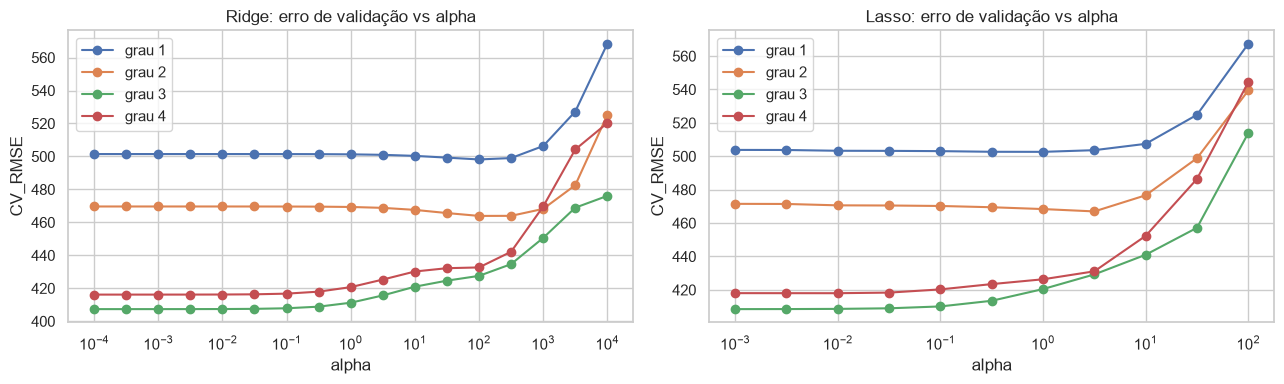

In [21]:
# Erro de validação (CV_RMSE) em função de alpha, para cada grau
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, gs, nome in zip(axes, [grid_search_ridge, grid_search_lasso], ["Ridge", "Lasso"]):
    res = pd.DataFrame(gs.cv_results_)
    for g in [1, 2, 3, 4]:
        s = res[res["param_prep__poly__pf__degree"] == g]
        ax.plot(s["param_modelo__alpha"].astype(float), -s["mean_test_score"], marker="o", label=f"grau {g}")
    ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.set_ylabel("CV_RMSE")
    ax.set_title(f"{nome}: erro de validação vs alpha"); ax.legend()
plt.tight_layout(); plt.show()

## 12. Resultados dos modelos lineares
### 12.1 Resultados e discussão
A introdução de termos polinomiais em temperatura e hora melhorou de forma clara o desempenho face à regressão linear. No teste, o R² passou de 0,488 para 0,577 e o MAE de 324 para 264 bicicletas por hora; na validação cruzada temporal, o R² médio subiu de 0,154 para 0,424. O Ridge e o Lasso selecionaram o grau 3 e valores de α muito pequenos (10⁻⁴ e 10⁻³), no limite inferior da grelha, e obtiveram resultados praticamente idênticos aos do polinómio de grau 3 sem regularização. O gráfico do erro de validação em função de α mostra, para o grau 3, um erro constante para α pequenos e crescente a partir de α próximo de 1.

Interpretamos este resultado como indicação de que, com 26 atributos e 6772 observações de treino, o modelo não sofre de sobreajuste suficiente para que a penalização reduza o erro de previsão. O ganho deve-se, portanto, ao polinómio e não à regularização. Esta mantém interesse na interpretação: perante a correlação de 0,93 entre temperatura e ponto de orvalho, o Lasso anulou o coeficiente do ponto de orvalho e concentrou o efeito na temperatura (secção 12.2).

Como limitações, o conjunto cobre apenas um ano e o período de teste, quase exclusivamente outono, não foi observado no treino e tem procura média superior (896 contra 688 bicicletas por hora). A validação cruzada temporal é por isso mais exigente do que o teste, uma vez que as primeiras partições treinam com poucos meses de inverno. O R² de cerca de 0,58 mostra ainda que há padrões que um modelo linear, mesmo com polinómio, não capta, o que justifica a comparação com modelos não lineares.

### 12.2 Coeficientes e viés no teste
Para comparar a regressão linear, o Ridge e o Lasso ao nível dos coeficientes usámos o modelo sem polinómio (grau 1), com todas as variáveis normalizadas, de modo que cada coeficiente representa o efeito, em bicicletas por hora, de aumentar um desvio-padrão na variável. Os valores de α (100 no Ridge e 5 no Lasso) são ilustrativos, escolhidos para tornar visível o efeito da penalização, e não os otimizados no `GridSearchCV`.

In [22]:
from sklearn.linear_model import LinearRegression
nomes = NUM_COLS + [c for c in FEATURES if c not in NUM_COLS]
modelos_coef = {"Linear": LinearRegression(), "Ridge (alpha=100)": Ridge(alpha=100),
                "Lasso (alpha=5)": Lasso(alpha=5, max_iter=20000)}
coefs = {}
for nome, mod in modelos_coef.items():
    p = Pipeline([("prep", make_preprocessor(scale=True)), ("modelo", mod)]).fit(X_train, y_train)
    coefs[nome] = p.named_steps["modelo"].coef_
tab_coef = pd.DataFrame(coefs, index=nomes).round(1)
print("Correlação temp vs dew_point (treino):", round(X_train["temp"].corr(X_train["dew_point"]), 3))
tab_coef

Correlação temp vs dew_point (treino): 0.926


,Linear,Ridge (alpha=100),Lasso (alpha=5)
temp,163.0,200.7,307.3
humidity,-212.1,-188.5,-135.6
wind,10.5,11.4,5.1
visibility,-2.9,7.8,9.7
dew_point,141.1,121.9,0.0
solar,-71.5,-59.4,-46.3
rain,-73.1,-72.1,-69.8
snow,19.5,16.4,9.2
hour,18.5,19.5,20.9
holiday,-116.4,-92.5,-12.0


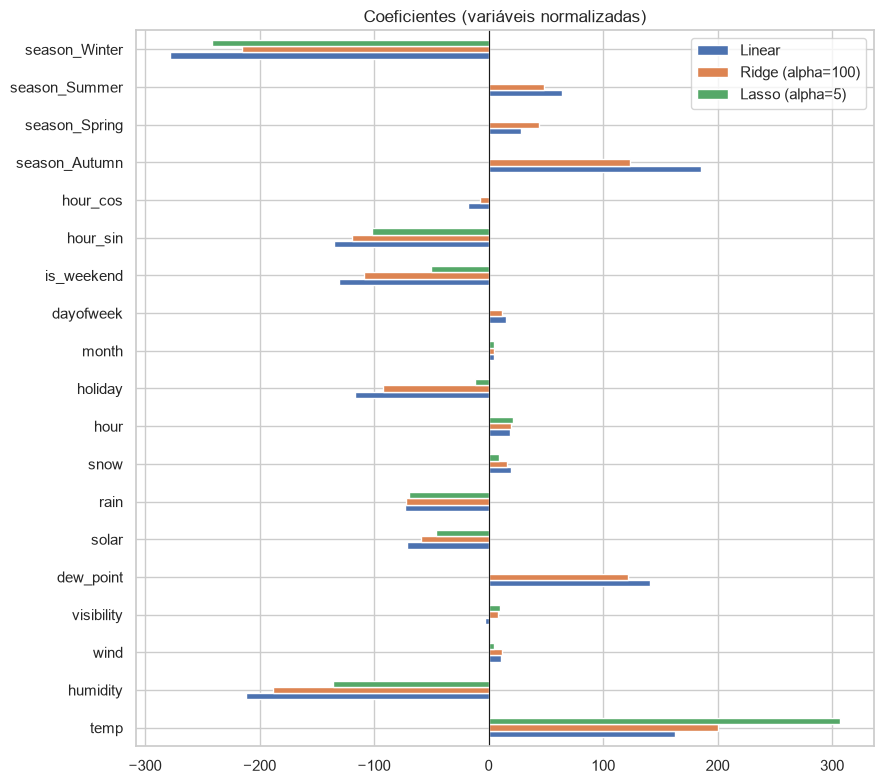

In [23]:
tab_coef.plot(kind="barh", figsize=(9, 8))
plt.title("Coeficientes (variáveis normalizadas)"); plt.axvline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

Verificámos também se os modelos subestimam ou sobrestimam de forma sistemática a procura no período de teste, que é quase só outono e tem procura média superior à do treino, e como o erro varia de mês para mês.

In [24]:
comp = pd.DataFrame({"mês": test["month"].values, "real": y_test.values,
                     "linear": pred_lin, "Ridge poli": pred_ridge, "Lasso poli": pred_lasso})
print("Média real no teste: %.1f | média do treino: %.1f" % (y_test.mean(), y_train.mean()))
print("\nMédia prevista no teste:"); print(comp[["linear", "Ridge poli", "Lasso poli"]].mean().round(1))
for c in ["linear", "Ridge poli", "Lasso poli"]:
    comp[f"erro_{c}"] = (comp["real"] - comp[c]).abs()
print("\nErro absoluto médio por mês (teste):")
comp.groupby("mês")[["real"] + [f"erro_{c}" for c in ["linear", "Ridge poli", "Lasso poli"]]].mean().round(1)

Média real no teste: 895.6 | média do treino: 687.5

Média prevista no teste:
linear        940.4
Ridge poli    833.3
Lasso poli    833.3
dtype: float64

Erro absoluto médio por mês (teste):


,real,erro_linear,erro_Ridge poli,erro_Lasso poli
mês,,,,
9,1052.2,364.8,311.5,311.5
10,978.5,316.2,281.4,281.4
11,718.7,308.8,219.5,219.5


A correlação entre `temp` e `dew_point` no treino é de 0,926, pelo que as duas variáveis transportam quase a mesma informação. Na regressão linear os dois coeficientes são positivos e partilham o efeito (163 e 141); o Ridge mantém ambos, redistribuindo o peso (201 e 122), enquanto o Lasso anula o do ponto de orvalho e atribui o efeito à temperatura (307), escolhendo uma das duas variáveis colineares. O Lasso anula ainda `dayofweek`, `hour_cos` e as estações primavera, verão e outono, ficando apenas o inverno com um efeito negativo forte (−242).

Quanto ao viés, a procura média real no teste é de 896 bicicletas por hora: a regressão linear sobrestima (940) e os polinómios subestimam (833). Ainda assim, o erro absoluto médio dos polinómios é inferior ao da regressão linear em todos os meses do teste (setembro 311 contra 365, outubro 281 contra 316, novembro 220 contra 309). Isto sugere que o ganho dos polinómios vem sobretudo da forma da relação com a hora e a temperatura, e não de acertarem no nível médio.

### 12.3 Tabela de resultados dos modelos lineares
Resumo comparativo dos modelos lineares. Esta tabela é partilhada com os restantes modelos do trabalho, o que permite compará-los nas mesmas métricas.

In [25]:
tabela_resultados()

,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
modelo,,,,,,
Baseline: média,491.506,634.409,-0.120,510.389,676.520,-0.466
Regressão linear (baseline),324.292,428.833,0.488,398.771,501.446,0.154
"Polinómio grau 1 (temp, hora)",324.292,428.833,0.488,398.771,501.446,0.154
"Polinómio grau 2 (temp, hora)",345.348,433.703,0.476,363.755,469.636,0.231
"Polinómio grau 3 (temp, hora)",264.460,389.743,0.577,310.045,407.358,0.424
"Polinómio grau 4 (temp, hora)",260.319,379.648,0.599,297.659,416.170,0.371
"Polinómio grau 5 (temp, hora)",249.887,364.623,0.630,312.066,493.122,-0.181
"Ridge poli (grau=3, alpha=0.0001)",264.460,389.743,0.577,310.045,407.359,0.424
"Lasso poli (grau=3, alpha=0.001)",264.457,389.750,0.577,310.525,408.452,0.422


### 12.4 Hora como variável categórica e interação com o fim de semana
O polinómio da secção 9 melhora a regressão linear, mas continua a descrever a hora com uma curva suave e igual para todos os dias, quando a EDA mostrou dois picos nos dias úteis (8h e 18h) e um só ao fim de semana. Testámos por isso representar a hora como **variável categórica** (one-hot, 24 valores) e, em alternativa, a **interação hora × tipo de dia** (48 valores: cada hora de dia útil e cada hora de fim de semana). Cada hora passa a ter o seu próprio efeito, sem se impor uma forma. A temperatura mantém-se em polinómio (grau 1 ou 3) e os restantes atributos como no baseline. O modelo continua linear nos coeficientes; o que muda é a representação da hora.

In [26]:
from sklearn.preprocessing import OneHotEncoder

# Variável auxiliar: hora x tipo de dia (0-23 = dia útil, 24-47 = fim de semana)
def com_hora_fds(X):
    X = X.copy()
    X["hour_we"] = X["hour"] + 24 * X["is_weekend"]
    return X

Xh_train, Xh_test = com_hora_fds(X_train), com_hora_fds(X_test)

COLS_BIN = [c for c in FEATURES if c.startswith("season_")] + ["holiday", "is_weekend"]
COLS_NUM_H = [c for c in NUM_COLS if c != "temp"] + ["month", "dayofweek"]

def make_prep_hora(col_hora, grau_temp):
    """Hora como categoria (one-hot) em vez de número; temperatura em polinómio; resto como no baseline.
    Usar dentro de Pipeline (scalers e encoder são ajustados só nos dados de treino de cada fold)."""
    temp_poly = Pipeline([("sc", StandardScaler()),
                          ("pf", PolynomialFeatures(degree=grau_temp, include_bias=False))])
    return ColumnTransformer([("temp", temp_poly, ["temp"]),
                              ("num", StandardScaler(), COLS_NUM_H),
                              ("hora", OneHotEncoder(handle_unknown="ignore"), [col_hora]),
                              ("bin", "passthrough", COLS_BIN)])

variantes = [("hora categórica (24), temp grau 1", "hour", 1),
             ("hora categórica (24), temp grau 3", "hour", 3),
             ("hora × fim de semana (48), temp grau 1", "hour_we", 1),
             ("hora × fim de semana (48), temp grau 3", "hour_we", 3)]
linhas_h = []
for nome, col, grau in variantes:
    m = Pipeline([("prep", make_prep_hora(col, grau)), ("modelo", LinearRegression())])
    r_h, _ = avaliar(m, f"Linear: {nome}", X_tr=Xh_train, X_te=Xh_test)
    linhas_h.append(r_h)
pd.concat(linhas_h).set_index("modelo")

,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
modelo,,,,,,
"Linear: hora categórica (24), temp grau 1",257.062,346.570,0.666,349.586,444.401,0.366
"Linear: hora categórica (24), temp grau 3",253.458,349.188,0.661,335.544,414.435,0.458
"Linear: hora × fim de semana (48), temp grau 1",228.398,314.401,0.725,336.447,428.789,0.418
"Linear: hora × fim de semana (48), temp grau 3",228.813,314.348,0.725,322.134,398.444,0.506


A representação da hora tem mais efeito do que o grau do polinómio. Com a hora categórica, o R² de teste sobe de 0,488 (baseline) para 0,666 e o RMSE desce de 429 para 347. Com a interação hora × fim de semana, o R² chega a 0,725 e o RMSE a 314 bicicletas por hora, e o `CV_RMSE` desce para 398 (contra 501 no baseline e 407 no melhor polinómio). Juntar um polinómio de grau 3 na temperatura melhora sobretudo a validação cruzada (de 429 para 398) e quase não altera o teste (RMSE de 314,4 e 314,3). Conclui-se que a principal fraqueza da regressão linear simples não é ser linear, mas descrever mal a hora do dia, cujo efeito depende do tipo de dia.

In [27]:
# Ridge com GridSearchCV sobre o melhor desenho (hora x fim de semana): grau da temperatura e alpha
pipeline_hwe = Pipeline([("prep", make_prep_hora("hour_we", 1)),
                         ("modelo", Ridge(random_state=RANDOM_STATE))])
param_grid_hwe = {
    "prep__temp__pf__degree": [1, 2, 3],
    "modelo__alpha": np.logspace(-2, 4, 13)
}
grid_search_hwe = GridSearchCV(pipeline_hwe, param_grid_hwe, cv=tscv,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)
grid_search_hwe.fit(Xh_train, y_train)

g_hwe = grid_search_hwe.best_params_["prep__temp__pf__degree"]
a_hwe = grid_search_hwe.best_params_["modelo__alpha"]
print(f"Melhor grau (temp): {g_hwe} | melhor alpha: {a_hwe:.4g} | CV_RMSE: {-grid_search_hwe.best_score_:.1f}")
r_hwe, pred_hwe = avaliar(grid_search_hwe.best_estimator_, f"Ridge: hora × fim de semana (grau={g_hwe}, alpha={a_hwe:.3g})",
                          X_tr=Xh_train, X_te=Xh_test)
tabela_resultados()

Melhor grau (temp): 3 | melhor alpha: 0.01 | CV_RMSE: 398.5


,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
modelo,,,,,,
Baseline: média,491.506,634.409,-0.120,510.389,676.520,-0.466
Regressão linear (baseline),324.292,428.833,0.488,398.771,501.446,0.154
"Polinómio grau 1 (temp, hora)",324.292,428.833,0.488,398.771,501.446,0.154
"Polinómio grau 2 (temp, hora)",345.348,433.703,0.476,363.755,469.636,0.231
"Polinómio grau 3 (temp, hora)",264.460,389.743,0.577,310.045,407.358,0.424
"Polinómio grau 4 (temp, hora)",260.319,379.648,0.599,297.659,416.170,0.371
"Polinómio grau 5 (temp, hora)",249.887,364.623,0.630,312.066,493.122,-0.181
"Ridge poli (grau=3, alpha=0.0001)",264.460,389.743,0.577,310.045,407.359,0.424
"Lasso poli (grau=3, alpha=0.001)",264.457,389.750,0.577,310.525,408.452,0.422


Aplicámos o Ridge com `GridSearchCV` ao melhor desenho (hora × fim de semana), pesquisando o grau da temperatura (1 a 3) e o α (de 10⁻² a 10⁴). Foram escolhidos o grau 3 e α = 0,01, no limite inferior da grelha, com resultados iguais aos do modelo sem regularização (R² de teste de 0,725 e `CV_RMSE` de 398). Tal como na secção 10, a regularização não reduz o erro de previsão: interpretamos que, mesmo com 48 categorias de hora, as 6772 observações de treino chegam para o modelo não sobreajustar, e o ganho deve-se à representação da hora e não à penalização.

Face ao Random Forest otimizado da Parte III (R² de teste ≈ 0,74 e RMSE ≈ 307), o melhor modelo linear fica muito próximo no teste (RMSE de 314), mas continua atrás na validação cruzada (`CV_RMSE` de 398 contra ≈ 289). Por isso não se pode concluir que os dois sejam equivalentes, mas também não é correto atribuir toda a vantagem do Random Forest ao facto de ser não linear: parte dela vem de os modelos lineares anteriores representarem mal a hora.

### 12.5 Onde falha a regressão linear: procura média por hora, real vs prevista
Para mostrar visualmente porque a regressão linear simples não capta a hora do dia, comparámos, no conjunto de teste, a procura média real em cada hora com a prevista por três modelos: a regressão linear, o polinómio com Ridge (secção 10) e o modelo com hora × fim de semana (secção 12.4), separando dias úteis e fins de semana.

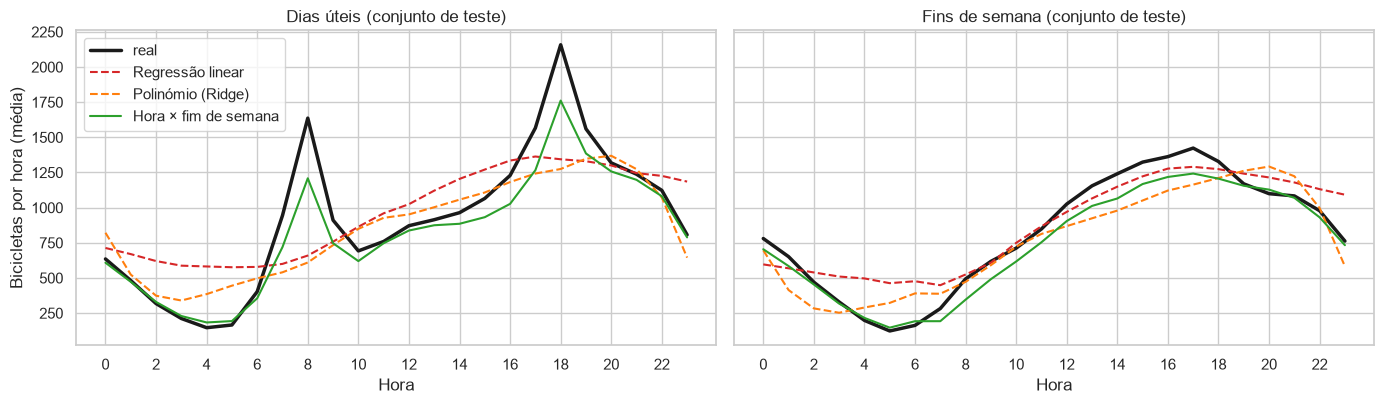

In [28]:
# Procura média por hora no conjunto de teste: real vs previsto, em dias úteis e fins de semana
dados_h = pd.DataFrame({"hora": test["hour"].values, "fds": test["is_weekend"].values,
                        "real": y_test.values,
                        "Regressão linear": pred_lin,
                        "Polinómio (Ridge)": pred_ridge,
                        "Hora × fim de semana": pred_hwe})
series_h = ["real", "Regressão linear", "Polinómio (Ridge)", "Hora × fim de semana"]
estilos = {"real": dict(color="k", lw=2.5), "Regressão linear": dict(color="tab:red", ls="--"),
           "Polinómio (Ridge)": dict(color="tab:orange", ls="--"),
           "Hora × fim de semana": dict(color="tab:green", ls="-")}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, (fds, titulo) in zip(axes, [(0, "Dias úteis"), (1, "Fins de semana")]):
    media_h = dados_h[dados_h["fds"] == fds].groupby("hora")[series_h].mean()
    for s in series_h:
        media_h[s].plot(ax=ax, label=s, **estilos[s])
    ax.set_title(f"{titulo} (conjunto de teste)"); ax.set_xlabel("Hora"); ax.set_xticks(range(0, 24, 2))
axes[0].set_ylabel("Bicicletas por hora (média)"); axes[0].legend()
plt.tight_layout(); plt.show()

Nos dias úteis, a procura real tem dois picos (8h: 1637 e 18h: 2158 bicicletas em média), que a regressão linear praticamente não acompanha (659 às 8h e 1344 às 18h) e que o polinómio também não (610 e 1275): ambos produzem uma curva suave, e a regressão linear prevê ainda muito mais procura do que a real de madrugada (582 às 4h contra 146). O modelo com hora × fim de semana reproduz os dois picos, embora os subestime (1209 às 8h e 1761 às 18h), e acompanha melhor a madrugada (184 às 4h). Ao fim de semana, onde a curva é mais suave, as diferenças entre os modelos são pequenas.

Isto responde à pergunta sobre porque a regressão linear não capta a hora do dia: uma única curva, comum a todos os dias, não consegue descrever picos diferentes consoante o tipo de dia. A subestimação dos picos, mesmo no melhor modelo, ajuda também a explicar porque os maiores erros se concentram nas horas de ponta, como se vê na análise de resíduos da Parte III.

# PARTE III — MODELOS NÃO LINEARES E DIAGNÓSTICO
Os modelos lineares mais simples não captam a forma da procura (dois picos na hora, queda com calor extremo). Nesta parte testamos **modelos baseados em árvores**: uma árvore parte os dados em grupos e prevê a média de cada grupo, por isso capta curvas e interações sem sermos nós a escolher que variáveis "dobrar".

**Regras seguidas:** mesmo split e mesma `avaliar()`; variantes e hiperparâmetros escolhidos pela **validação cruzada temporal** (`tscv`) com **RMSE** (o critério pensado para ser o mesmo dos modelos lineares); o **teste só mede**.

### Resumo das decisões
| Decisão | Escolha | Porquê | Onde se vê |
| --- | --- | --- | --- |
| Tipo de modelo | Árvore e Random Forest | A procura não é linear; a média de muitas árvores reduz o overfitting de uma só | 13 e 14 |
| Normalização | Não | As árvores comparam cada variável com limiares; a escala não muda o resultado | 13.2 |
| `log1p` no alvo | Não usar | Piora o erro no teste e não melhora a validação cruzada | 14.2 |
| `dew_point` | Retirar | Correlação ≈ 0,9 com `temp`; sem perda de desempenho, modelo mais simples | 14.2 |
| Critério de escolha | RMSE na validação cruzada temporal | Está em bicicletas/hora e penaliza mais os erros grandes | 15 |
| Hiperparâmetros | `GridSearchCV` (`n_estimators` fixo em 300) | Mais árvores só reduzem a variância; o resto escolhe-se na validação cruzada | 15 |
| Papel do teste | Só medir | Escolher pelo teste seria fuga de informação | Todas |
| Variável `month` | Manter | Retirá-la piora o modelo | 17.4 |

## 13. Árvore de Decisão (DecisionTreeRegressor)
### 13.1 Porquê árvores: o que os dados mostram
Se a procura tiver dois picos ao longo do dia e descer com calor extremo, uma linha reta não a descreve e uma árvore consegue. (A EDA detalhada, por dia útil e fim de semana e por estação, está na secção 8; aqui só confirmamos o que interessa às árvores.)

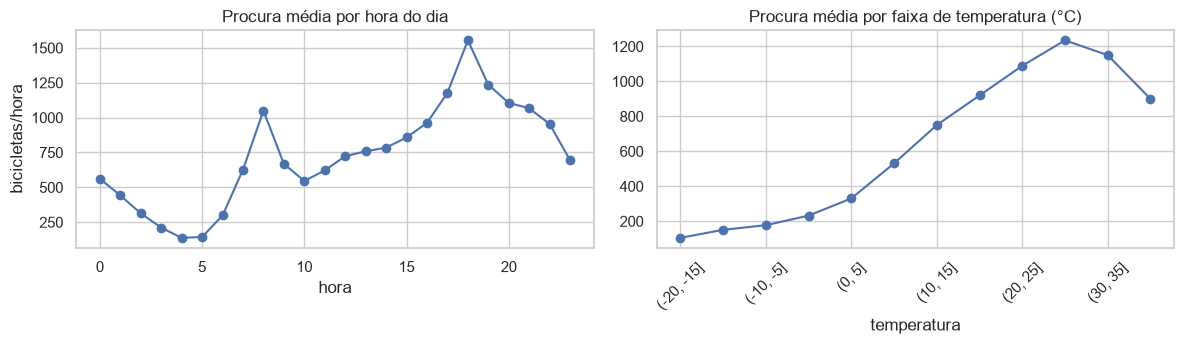

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
df.groupby("hour")["count"].mean().plot(ax=ax[0], marker="o")
ax[0].set_title("Procura média por hora do dia"); ax[0].set_xlabel("hora"); ax[0].set_ylabel("bicicletas/hora")
df.groupby(pd.cut(df["temp"], bins=range(-20, 45, 5)), observed=True)["count"].mean().plot(ax=ax[1], marker="o")
ax[1].set_title("Procura média por faixa de temperatura (°C)"); ax[1].set_xlabel("temperatura"); ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**Como ler.** À esquerda, cada ponto é a procura média numa hora do dia: há **dois picos** (por volta das 8h e das 18h, deslocações para o trabalho). À direita, cada ponto é a procura média numa faixa de 5 °C: sobe até ~25–30 °C e **desce** a partir daí. Nenhuma das duas relações é uma linha reta.

### 13.2 Árvore sem limite de profundidade
Em regressão, cada folha devolve a **média** dos valores de treino que lá caíram. Sem limite de profundidade a árvore continua a dividir até ficar quase com uma folha por observação e **memoriza o treino** (overfitting). Medimos isto comparando o erro no treino com o erro no teste.

**O que o código faz.** `modelo_arvore` cria um `Pipeline` sem normalização (as árvores não precisam). `treino_vs_teste` treina o modelo e devolve MAE, RMSE e R² no treino e no teste.

In [30]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance

def modelo_arvore(modelo):
    """Árvores não precisam de normalização: o pré-processamento é 'passthrough'."""
    return Pipeline([("prep", make_preprocessor(scale=False)), ("modelo", modelo)])

def treino_vs_teste(modelo, X_tr, X_te, nome=""):
    """Erro no treino vs teste do mesmo modelo: se o treino for muito melhor, há overfitting."""
    modelo.fit(X_tr, y_train)
    out = {}
    for conj, X, y in [("treino", X_tr, y_train), ("teste", X_te, y_test)]:
        p = np.clip(modelo.predict(X), 0, None)
        out[conj] = {"MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)), "R2": r2_score(y, p)}
    return pd.DataFrame(out).T.round(3).rename_axis(nome)

dt = modelo_arvore(DecisionTreeRegressor(random_state=RANDOM_STATE))
r, _ = avaliar(dt, "Árvore (default, sem limite)")
display(r)
treino_vs_teste(dt, X_train, X_test, "Árvore sem limite")

,modelo,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
0,"Árvore (default, sem limite)",291.913,402.226,0.55,238.651,348.775,0.568


,MAE,RMSE,R2
Árvore sem limite,,,
treino,0.000,0.000,1.00
teste,291.913,402.226,0.55


A árvore sem limite isola cada hora do treino numa folha, por isso no treino acerta sempre (R² 1,00). Em horas novas não consegue, e o R² cai para 0,55. É sobreajuste, e é por isso que avaliamos no CV e no teste, não no treino.

## 14. Random Forest Regressor
### 14.1 Random Forest com valores por defeito
Um Random Forest treina muitas árvores, cada uma numa amostra diferente dos dados e com um subconjunto aleatório de variáveis em cada divisão, e **faz a média das previsões**. Como os erros de cada árvore são em parte independentes, a média é mais estável do que uma árvore sozinha, e isto reduz o overfitting.

In [31]:
rf = modelo_arvore(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
r, _ = avaliar(rf, "Random Forest (default)")
display(r)
treino_vs_teste(rf, X_train, X_test, "Random Forest default")

,modelo,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
0,Random Forest (default),220.571,309.077,0.734,205.166,289.835,0.695


,MAE,RMSE,R2
Random Forest default,,,
treino,33.926,60.788,0.991
teste,220.571,309.077,0.734


**Como ler.** O R² no teste sobe de ≈ 0,57 (uma árvore) para ≈ 0,73. O treino continua a ser melhor do que o teste (R² ≈ 0,99), mas o teste é muito superior ao de uma árvore sozinha: é o efeito de fazer a média de muitas árvores.

### 14.2 Duas decisões: `log1p` no alvo e retirar `dew_point`
Decididas **pela validação cruzada temporal** e comparadas também no teste.

- **`log1p` no alvo.** O alvo tem cauda longa e treinar sobre `log1p(y)` reduz o peso dos picos. `TransformedTargetRegressor` treina em escala logarítmica e devolve as previsões à escala original, o que permite calcular métricas e validação cruzada em bicicletas/hora, comparáveis com os restantes modelos.
- **Retirar `dew_point`.** Tem correlação ≈ 0,9 com `temp` (quase a mesma informação). Para árvores a colinearidade pesa pouco na previsão, mas partilha a importância entre as duas variáveis e dificulta a interpretação. Se retirar não piorar, o modelo fica mais simples.

In [32]:
rf_log = TransformedTargetRegressor(
    regressor=modelo_arvore(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
    func=np.log1p, inverse_func=np.expm1)
avaliar(rf_log, "RF + log1p no alvo")

FEATURES_SEM_DEW = [c for c in FEATURES if c != "dew_point"]
rf_sem = modelo_arvore(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
avaliar(rf_sem, "RF sem dew_point", X_tr=X_train[FEATURES_SEM_DEW], X_te=X_test[FEATURES_SEM_DEW])

tabela_resultados().loc[["Árvore (default, sem limite)", "Random Forest (default)",
                         "RF + log1p no alvo", "RF sem dew_point"]]

,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
modelo,,,,,,
"Árvore (default, sem limite)",291.913,402.226,0.550,238.651,348.775,0.568
Random Forest (default),220.571,309.077,0.734,205.166,289.835,0.695
RF + log1p no alvo,252.219,357.306,0.645,203.686,295.666,0.685
RF sem dew_point,214.640,304.887,0.741,205.012,290.242,0.695


**Decisão (ver a tabela):**
- **`log1p`: não usar.** Não melhora a validação cruzada e piora o erro no teste, porque minimiza o erro em escala logarítmica, que dá menos peso aos picos, justamente os erros mais caros em bicicletas/hora.
- **`dew_point`: retirar.** O erro fica praticamente igual (diferença pequena, dentro do ruído); o modelo fica mais simples e fácil de interpretar. A decisão baseia-se em simplicidade, não num ganho claro de precisão.

A partir daqui usamos `FEATURES_B` = todas as variáveis menos `dew_point`.

In [33]:
FEATURES_B = FEATURES_SEM_DEW
XB_train, XB_test = X_train[FEATURES_B], X_test[FEATURES_B]
print(len(FEATURES_B), "variáveis:", FEATURES_B)

18 variáveis: ['hour', 'temp', 'humidity', 'wind', 'visibility', 'solar', 'rain', 'snow', 'holiday', 'month', 'dayofweek', 'is_weekend', 'hour_sin', 'hour_cos', 'season_Autumn', 'season_Spring', 'season_Summer', 'season_Winter']


## 15. Otimização com `GridSearchCV` (Árvore e Random Forest)
Como na Aula 3, testamos combinações de hiperparâmetros com validação cruzada, **só nos dados de treino** e com `cv=tscv`. Critério: RMSE.

**Hiperparâmetros e porquê:**
- `max_depth`: profundidade máxima das árvores; limita a complexidade e controla o overfitting.
- `min_samples_leaf`: mínimo de observações por folha; folhas maiores = médias mais estáveis = menos overfitting.
- `max_features` (só Random Forest): fração de variáveis consideradas em cada divisão; valores baixos tornam as árvores mais diferentes entre si e reforçam o efeito da média.
- `n_estimators` (só Random Forest): fixámos em 300. Mais árvores só reduzem a variância e nunca causam overfitting; acima de umas centenas o ganho é desprezável e o tempo cresce.

**O que o código faz.** `GridSearchCV` treina cada combinação em cada um dos 5 folds, calcula o RMSE de validação e escolhe a combinação de menor RMSE médio (`scoring` negativo porque o `GridSearchCV` maximiza). `best_estimator_` é depois avaliado com `avaliar()`.

### 15.1 Árvore de decisão

In [34]:
grid_dt = GridSearchCV(
    modelo_arvore(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    {"modelo__max_depth": [3, 5, 8, 12, None], "modelo__min_samples_leaf": [1, 5, 10, 20]},
    cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)
grid_dt.fit(XB_train, y_train)
print("Árvore — melhores:", grid_dt.best_params_, "| CV_RMSE: %.1f" % -grid_dt.best_score_)
avaliar(grid_dt.best_estimator_, "Árvore otimizada", X_tr=XB_train, X_te=XB_test)[0]

Árvore — melhores: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 5} | CV_RMSE: 331.8


,modelo,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
0,Árvore otimizada,253.923,360.573,0.638,230.371,331.795,0.607


### 15.2 Random Forest

In [35]:
# n_jobs=1 no modelo e n_jobs=-1 na grelha, para não paralelizar duas vezes
grid_rf = GridSearchCV(
    modelo_arvore(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
    {"modelo__max_depth": [8, 12, None],
     "modelo__min_samples_leaf": [1, 3, 5, 10],
     "modelo__max_features": [0.5, 1.0]},
    cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)
print("A treinar o Random Forest (24 combinações × 5 folds)...")
grid_rf.fit(XB_train, y_train)
print("RF — melhores:", grid_rf.best_params_, "| CV_RMSE: %.1f" % -grid_rf.best_score_)
r_rf, pred_rf = avaliar(grid_rf.best_estimator_, "RF otimizado", X_tr=XB_train, X_te=XB_test)
display(r_rf)

A treinar o Random Forest (24 combinações × 5 folds)...
RF — melhores: {'modelo__max_depth': None, 'modelo__max_features': 1.0, 'modelo__min_samples_leaf': 1} | CV_RMSE: 289.4


,modelo,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
0,RF otimizado,217.296,307.791,0.736,204.095,289.353,0.696


In [36]:
# Erro de validação de cada combinação (para ver se o melhor valor está no limite da grelha)
res = pd.DataFrame(grid_rf.cv_results_)[["param_modelo__max_depth", "param_modelo__min_samples_leaf",
                                          "param_modelo__max_features", "mean_test_score"]]
res["CV_RMSE"] = -res.pop("mean_test_score")
res.sort_values("CV_RMSE").head(8).round(1).reset_index(drop=True)

,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__max_features,CV_RMSE
0,None,1,1.0,289.4
1,12,1,1.0,291.7
2,None,3,1.0,294.7
3,12,3,1.0,296.0
4,None,1,0.5,296.5
5,12,1,0.5,299.8
6,None,5,1.0,304.3
7,8,1,1.0,305.0


In [37]:
treino_vs_teste(grid_rf.best_estimator_, XB_train, XB_test, "RF otimizado")

,MAE,RMSE,R2
RF otimizado,,,
treino,33.224,59.561,0.991
teste,217.296,307.791,0.736


**Como ler.** A tabela das 8 melhores combinações mostra o RMSE de validação de cada uma. A melhor (`max_depth=None`, `min_samples_leaf=1`, `max_features=1.0`) é o **extremo da grelha** e coincide com os valores por defeito: limitar a profundidade ou aumentar as folhas piorou a validação cruzada. O ganho da otimização é pequeno (CV_RMSE ≈ 289 contra ≈ 291 sem otimizar); o que faz a diferença é o tipo de modelo, não o ajuste fino.

## 16. Importância das Variáveis (Feature Importance)
Duas medidas, para não depender de uma só:
- **Importância por impureza** (do Random Forest): quanto cada variável reduz o erro nas divisões das árvores. É rápida, mas favorece variáveis com muitos valores distintos e reparte-se entre variáveis correlacionadas.
- **Importância por permutação** (no teste): baralha uma variável de cada vez e mede quanto o RMSE piora, em bicicletas/hora. Mede o efeito na previsão e não só nas divisões.

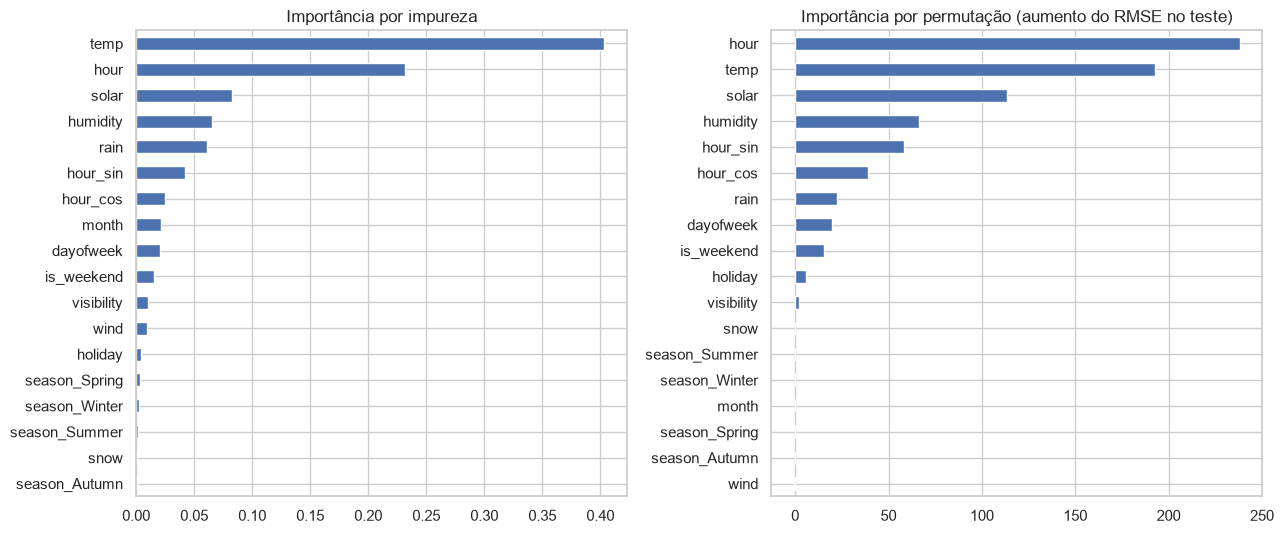

In [38]:
best_rf = grid_rf.best_estimator_
imp = pd.Series(best_rf.named_steps["modelo"].feature_importances_, index=FEATURES_B).sort_values()
perm = permutation_importance(best_rf, XB_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=FEATURES_B).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
imp.plot.barh(ax=ax[0]); ax[0].set_title("Importância por impureza")
imp_perm.plot.barh(ax=ax[1]); ax[1].set_title("Importância por permutação (aumento do RMSE no teste)")
plt.tight_layout(); plt.show()

A impureza mede, no treino, quanto cada variável ajudou a dividir os dados. A permutação mede, no teste, quanto sobe o erro quando se baralha essa variável. Dão ordens ligeiramente diferentes, mas concordam que a hora e a temperatura são as mais importantes.


## 17. Análise de Resíduos e Diagnóstico de Erros
Aqui perguntamos **onde e porquê** o modelo falha. Comparamos o Random Forest otimizado com a regressão linear de referência (7.2).

### 17.1 Erro por hora e por mês no teste
**O que o código faz.** Calcula o erro absoluto de cada previsão no teste e faz a média por hora e por mês, para os dois modelos.

Média real no teste: 895.6 | prevista RF: 777.0 | prevista Regressão linear: 940.4


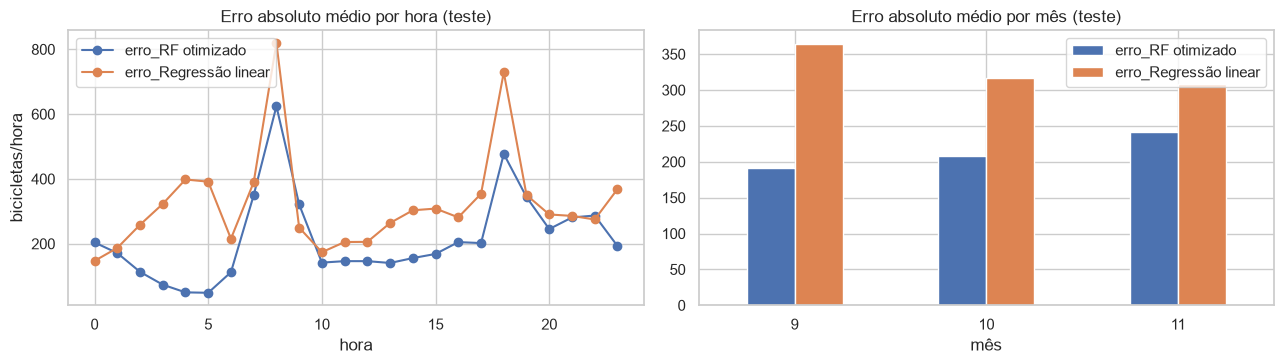

,real,erro_RF otimizado,erro_Regressão linear
mês,,,
9,1052.2,191.4,364.8
10,978.5,208.6,316.2
11,718.7,241.4,308.8


In [39]:
comp_b = pd.DataFrame({"hora": test["hour"].values, "mês": test["month"].values, "real": y_test.values,
                       "RF otimizado": pred_rf, "Regressão linear": pred_lin})
for c in ["RF otimizado", "Regressão linear"]:
    comp_b[f"erro_{c}"] = (comp_b["real"] - comp_b[c]).abs()

print("Média real no teste: %.1f | prevista RF: %.1f | prevista Regressão linear: %.1f"
      % (comp_b["real"].mean(), comp_b["RF otimizado"].mean(), comp_b["Regressão linear"].mean()))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
comp_b.groupby("hora")[["erro_RF otimizado", "erro_Regressão linear"]].mean().plot(ax=ax[0], marker="o")
ax[0].set_title("Erro absoluto médio por hora (teste)"); ax[0].set_ylabel("bicicletas/hora")
comp_b.groupby("mês")[["erro_RF otimizado", "erro_Regressão linear"]].mean().plot.bar(ax=ax[1], rot=0)
ax[1].set_title("Erro absoluto médio por mês (teste)")
plt.tight_layout(); plt.show()
comp_b.groupby("mês")[["real", "erro_RF otimizado", "erro_Regressão linear"]].mean().round(1)

**Como ler.**
- *Por hora:* o erro do Random Forest é maior às **8h e às 18h**, as horas de maior procura, e pequeno de madrugada. Fica abaixo do da regressão linear em quase todas as horas.
- *Por mês:* o Random Forest erra menos do que a regressão linear em setembro, outubro e novembro.
- *Viés:* a média prevista (≈ 778) é inferior à real (≈ 896): o modelo **subestima** a procura no teste.

### 17.2 Porque é que o Random Forest subestima a procura no outono?
O treino cobre sobretudo inverno, primavera e verão, e o teste é outono. Verificamos se, **para a mesma temperatura (sem chuva)**, a procura média no teste é diferente da do treino. Se for, o modelo aprendeu níveis de procura que já não são os do outono.

In [40]:
faixas = pd.cut(df["temp"], bins=[-20, 0, 5, 10, 15, 20, 25, 30, 40])
conj = np.where(df["datetime"] >= test["datetime"].min(), "teste", "treino")
sem_chuva = (df["rain"] == 0)
comp_temp = (df[sem_chuva].assign(faixa=faixas[sem_chuva], conj=conj[sem_chuva])
             .groupby(["faixa", "conj"], observed=True)["count"].agg(["mean", "size"]).round(0).unstack("conj"))
comp_temp

mean           size        
conj       teste  treino  teste  treino
faixa                                  
(-20, 0]   608.0   194.0   22.0  1415.0
(0, 5]     545.0   286.0  212.0   812.0
(5, 10]    720.0   440.0  424.0   568.0
(10, 15]   919.0   686.0  407.0   474.0
(15, 20]  1146.0   947.0  309.0   696.0
(20, 25]  1348.0  1213.0  196.0   963.0
(25, 30]  1661.0  1239.0   47.0   897.0
(30, 40]     NaN  1106.0    NaN   507.0

**Como ler.** Em cada linha (faixa de temperatura) comparamos a procura média no teste e no treino (`mean`) e o número de horas de cada (`size`). Para as mesmas temperaturas, a procura no teste é bastante superior (por exemplo, 10–15 °C: 919 contra 686; 5–10 °C: 720 contra 440). O modelo aprendeu os níveis do treino e por isso subestima o outono.

### 17.3 Overfitting

A tabela da secção 15.2 (treino contra teste) mostra R² ≈ 0,99 no treino e ≈ 0,74 no teste. Num Random Forest isto é esperado (cada árvore vê os dados de treino); o que importa é que a validação cruzada (R² ≈ 0,70) e o teste concordam, e que ambos superam claramente o modelo linear.

### 17.4 Verificação: a variável `month` é a causa?
Os meses 10 e 11 não aparecem no treino, e a variável `month` poderia induzir o erro. Testamos retirá-la.

In [41]:
FEATURES_SEM_DEW_MONTH = [c for c in FEATURES_B if c != "month"]
rf_sem_month = modelo_arvore(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
avaliar(rf_sem_month, "RF sem dew_point nem month",
        X_tr=X_train[FEATURES_SEM_DEW_MONTH], X_te=X_test[FEATURES_SEM_DEW_MONTH])
tabela_resultados().loc[["RF sem dew_point", "RF sem dew_point nem month"]]

,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
modelo,,,,,,
RF sem dew_point,214.640,304.887,0.741,205.012,290.242,0.695
RF sem dew_point nem month,246.383,332.265,0.693,208.914,294.226,0.684


**Resultado:** retirar `month` piora o modelo no teste e na validação cruzada, por isso a ausência de outubro e novembro no treino **não** é a causa da subestimação e mantemos a variável. A explicação que os dados suportam é a de 17.2.

# PARTE IV — SÍNTESE COMPARATIVA E CONCLUSÕES

## 18. Tabela Geral de Resultados de Todos os Modelos
`MAE`, `RMSE` e `R2` são medidos no **teste**; as colunas `CV_` são a média dos 5 folds da validação cruzada temporal, só no treino. MAE e RMSE: quanto menor, melhor (em bicicletas/hora); R²: quanto mais perto de 1, melhor.

In [42]:
tabela_resultados()

,MAE,RMSE,R2,CV_MAE,CV_RMSE,CV_R2
modelo,,,,,,
Baseline: média,491.506,634.409,-0.120,510.389,676.520,-0.466
Regressão linear (baseline),324.292,428.833,0.488,398.771,501.446,0.154
"Polinómio grau 1 (temp, hora)",324.292,428.833,0.488,398.771,501.446,0.154
"Polinómio grau 2 (temp, hora)",345.348,433.703,0.476,363.755,469.636,0.231
"Polinómio grau 3 (temp, hora)",264.460,389.743,0.577,310.045,407.358,0.424
"Polinómio grau 4 (temp, hora)",260.319,379.648,0.599,297.659,416.170,0.371
"Polinómio grau 5 (temp, hora)",249.887,364.623,0.630,312.066,493.122,-0.181
"Ridge poli (grau=3, alpha=0.0001)",264.460,389.743,0.577,310.045,407.359,0.424
"Lasso poli (grau=3, alpha=0.001)",264.457,389.750,0.577,310.525,408.452,0.422
